In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from functools import reduce
from scipy.cluster import hierarchy

In [3]:
import os
os.environ["PATH"] = "/home/irati/homer/bin:" + os.environ["PATH"]

# IFNg Upregulated genes motif analysis (1h stimulation)

## Load upregulated genes data

In [4]:
import os
import pandas as pd
import glob

In [5]:
# Folder path
folder = "Upregulated_"

# Find all files ending with "IFNg.csv" inside the folder
file_paths = glob.glob(os.path.join(folder, "*_IFNg.csv"))

# Dictionary to store columns for the DataFrame
gene_data = {}

# Loop through each file
for path in file_paths:
    # Extract the label from the filename (e.g., T419R from Upregulated_T419R_IFNg.csv)
    filename = os.path.basename(path)
    label = filename.split("_")[1]  # Assumes pattern: Upregulated_<label>_IFNg.csv
    
    # Read only the first column as a flat Series
    genes = pd.read_csv(path, header=0, usecols=[0]).squeeze("columns").dropna().reset_index(drop=True)
    
    # Store in dictionary
    gene_data[label] = genes

# Create DataFrame from dictionary (columns aligned by index)
df_up_IFNg = pd.DataFrame(gene_data)

In [6]:
df_up_IFNg.head()

,N574I,Y701A,WT,NT,T385M,T419R,S466R,R274W,R321S,H328R,M325K
0,CXCL9,IRF1,CXCL9,ENSG00000283648,APOL4,STEAP4,CXCL9,APOL4,APOL4,STEAP4,CXCL9
1,STEAP4,IRF9,STEAP4,CXCL9,STEAP4,CXCL9,FCGR2B,STEAP4,STEAP4,CXCL9,STEAP4
2,ENSG00000283648,REC8,ENSG00000283648,STEAP4,TBX21,GBP1,APOL4,CXCL9,CXCL9,TM4SF1,APOL4
3,CFH,ENSG00000259529,APOL4,TBX21,CD274,APOL4,STEAP4,CXCL10,LHX9,APOL4,FGF10
4,ENSG00000278058,ICAM1,ANKRD22,APOL4,CXCL9,CD274,NUDT10,LRRC77P,CD274,ACOD1,HCAR1


In [7]:
df_up_IFNg.shape

(249, 11)

In [8]:
df_up_IFNg.columns

Index(['N574I', 'Y701A', 'WT', 'NT', 'T385M', 'T419R', 'S466R', 'R274W',
       'R321S', 'H328R', 'M325K'],
      dtype='object')

## All mutations

Extract upregulated gene lists.

In [9]:
cols = df_up_IFNg.columns
cols 

Index(['N574I', 'Y701A', 'WT', 'NT', 'T385M', 'T419R', 'S466R', 'R274W',
       'R321S', 'H328R', 'M325K'],
      dtype='object')

In [10]:
for col in cols :
    df_up_IFNg[col].dropna().to_csv(f'up_IFNg/up_{col}.txt', index=False, header=False)

Find motifs with the default promoter region (-300, +50).

In [11]:
for col in cols:
    cmd = f"findMotifs.pl up_IFNg/up_{col}.txt human up_IFNg/up_{col}/ -p 14 &> log/log_findMotifs_{col}_IFNg_up.log"
    !{cmd}

In [12]:
for col in cols:
    cmd = f"findMotifs.pl up_IFNg/up_{col}.txt human up_IFNg/up_{col}_200_50/ -p 14 -start -200 -end 50 &> log/log_findMotifs_{col}_IFNg_up_200_50.log"
    !{cmd}

### Known motifs

In [11]:
motif_dfs = {}

for col in cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    motif_dfs[key_motifs] = pd.read_csv(f"up_IFNg/up_{col}/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    motif_dfs[key_motifs_200_50] = pd.read_csv(f"up_IFNg/up_{col}_200_50/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs_200_50].shape)


N574I_motifs
(472, 9)
N574I_motifs_200_50
(472, 9)
Y701A_motifs
(472, 9)
Y701A_motifs_200_50
(472, 9)
WT_motifs
(472, 9)
WT_motifs_200_50
(472, 9)
NT_motifs
(472, 9)
NT_motifs_200_50
(472, 9)
T385M_motifs
(472, 9)
T385M_motifs_200_50
(472, 9)
T419R_motifs
(472, 9)
T419R_motifs_200_50
(472, 9)
S466R_motifs
(472, 9)
S466R_motifs_200_50
(472, 9)
R274W_motifs
(472, 9)
R274W_motifs_200_50
(472, 9)
R321S_motifs
(472, 9)
R321S_motifs_200_50
(472, 9)
H328R_motifs
(472, 9)
H328R_motifs_200_50
(472, 9)
M325K_motifs
(472, 9)
M325K_motifs_200_50
(472, 9)


In [12]:
motif_dfs.keys()

dict_keys(['N574I_motifs', 'N574I_motifs_200_50', 'Y701A_motifs', 'Y701A_motifs_200_50', 'WT_motifs', 'WT_motifs_200_50', 'NT_motifs', 'NT_motifs_200_50', 'T385M_motifs', 'T385M_motifs_200_50', 'T419R_motifs', 'T419R_motifs_200_50', 'S466R_motifs', 'S466R_motifs_200_50', 'R274W_motifs', 'R274W_motifs_200_50', 'R321S_motifs', 'R321S_motifs_200_50', 'H328R_motifs', 'H328R_motifs_200_50', 'M325K_motifs', 'M325K_motifs_200_50'])

In [13]:
motif_keys = list(motif_dfs.keys()) 
comparison = motif_dfs[motif_keys[0]].drop_duplicates(subset="Motif Name").copy()
comparison.name = motif_keys[0].replace('_motifs', '')

# Merge with the rest
for key in motif_keys[1:]:
    right_df = motif_dfs[key].drop_duplicates(subset="Motif Name")
    right_df.name = key.replace('_motifs', '')
    comparison = pd.merge(
        comparison,
        right_df,
        on="Motif Name",
        how="outer",
        suffixes=(f"_{comparison.name}", f"_{right_df.name}")
    )
    comparison.name = right_df.name  

In [14]:
comparison.columns

Index(['Motif Name', 'Consensus_N574I', 'P-value_N574I', 'Log P-value_N574I',
       'q-value (Benjamini)_N574I',
       '# of Target Sequences with Motif(of 104)_N574I',
       '% of Target Sequences with Motif_N574I',
       '# of Background Sequences with Motif(of 45756)',
       '% of Background Sequences with Motif_N574I', 'Consensus_N574I_200_50',
       ...
       '# of Background Sequences with Motif(of 45468)',
       '% of Background Sequences with Motif_M325K', 'Consensus_M325K_200_50',
       'P-value_M325K_200_50', 'Log P-value_M325K_200_50',
       'q-value (Benjamini)_M325K_200_50',
       '# of Target Sequences with Motif(of 101)_M325K_200_50',
       '% of Target Sequences with Motif_M325K_200_50',
       '# of Background Sequences with Motif(of 45449)',
       '% of Background Sequences with Motif_M325K_200_50'],
      dtype='object', length=177)

#### Filter by p-value

In [15]:
# Select columns: 'Motif Name' and all 'P-value_{mutation}' columns
pvalue_cols = [col for col in comparison.columns if col.startswith('P-value_')]

# Create a DataFrame with only the relevant columns
df_pvalues = comparison[['Motif Name'] + pvalue_cols].copy()

In [16]:
df_pvalues.head()

,Motif Name,P-value_N574I,P-value_N574I_200_50,P-value_Y701A,P-value_Y701A_200_50,P-value_WT,P-value_WT_200_50,P-value_NT,P-value_NT_200_50,P-value_T385M,...,P-value_S466R,P-value_S466R_200_50,P-value_R274W,P-value_R274W_200_50,P-value_R321S,P-value_R321S_200_50,P-value_H328R,P-value_H328R_200_50,P-value_M325K,P-value_M325K_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,0.1,1.0,1.0,1.0
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [17]:
# Filter for rows where any P-value column is less than or equal to 0.05
df_pvalues_filtered = df_pvalues[df_pvalues[pvalue_cols].astype(float).le(0.05).any(axis=1)]
df_pvalues_filtered.head()

,Motif Name,P-value_N574I,P-value_N574I_200_50,P-value_Y701A,P-value_Y701A_200_50,P-value_WT,P-value_WT_200_50,P-value_NT,P-value_NT_200_50,P-value_T385M,...,P-value_S466R,P-value_S466R_200_50,P-value_R274W,P-value_R274W_200_50,P-value_R321S,P-value_R321S_200_50,P-value_H328R,P-value_H328R_200_50,P-value_M325K,P-value_M325K_200_50
9,Ascl2(bHLH)/ESC-Ascl2-ChIP-Seq(GSE97712)/Homer,1.00,1.00,1.0,1.0,0.10,1.00,0.1,1.00,0.1000,...,1.000,1.000,1.000,1.000,1.00,1.000,1.00,1.00,1.00,1.00
15,Atoh1(bHLH)/Cerebellum-Atoh1-ChIP-Seq(GSE22111...,1.00,1.00,1.0,1.0,0.01,0.10,0.1,0.10,1.0000,...,0.100,1.000,1.000,1.000,1.00,1.000,1.00,1.00,1.00,1.00
20,BMAL1(bHLH)/Liver-Bmal1-ChIP-Seq(GSE39860)/Homer,0.10,1.00,1.0,1.0,0.10,0.01,0.1,0.10,0.1000,...,1.000,1.000,0.100,1.000,0.10,1.000,1.00,0.10,0.10,1.00
27,Bcl11a(Zf)/HSPC-BCL11A-ChIP-Seq(GSE104676)/Homer,1.00,1.00,1.0,1.0,0.01,0.10,0.1,0.10,0.1000,...,1.000,1.000,0.100,1.000,1.00,1.000,1.00,1.00,0.10,1.00
28,Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0.01,0.01,1.0,1.0,0.10,0.10,0.1,0.01,0.0001,...,0.001,0.001,0.001,0.001,0.01,0.001,0.01,0.01,0.01,0.01


In [18]:
# Pivot the DataFrame to have 'Motif Name' as index and mutations as columns
# Extract mutation names from column names (e.g., 'P-value_WT' -> 'WT')
df_pvalues_filtered.columns = ['Motif Name'] + [col.replace('P-value_', '') for col in df_pvalues.columns if col.startswith('P-value_')]
df_pivot = df_pvalues_filtered.set_index('Motif Name')
df_pivot.head()

,N574I,N574I_200_50,Y701A,Y701A_200_50,WT,WT_200_50,NT,NT_200_50,T385M,T385M_200_50,...,S466R,S466R_200_50,R274W,R274W_200_50,R321S,R321S_200_50,H328R,H328R_200_50,M325K,M325K_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,,
Ascl2(bHLH)/ESC-Ascl2-ChIP-Seq(GSE97712)/Homer,1.00,1.00,1.0,1.0,0.10,1.00,0.1,1.00,0.1000,0.1000,...,1.000,1.000,1.000,1.000,1.00,1.000,1.00,1.00,1.00,1.00
Atoh1(bHLH)/Cerebellum-Atoh1-ChIP-Seq(GSE22111)/Homer,1.00,1.00,1.0,1.0,0.01,0.10,0.1,0.10,1.0000,1.0000,...,0.100,1.000,1.000,1.000,1.00,1.000,1.00,1.00,1.00,1.00
BMAL1(bHLH)/Liver-Bmal1-ChIP-Seq(GSE39860)/Homer,0.10,1.00,1.0,1.0,0.10,0.01,0.1,0.10,0.1000,0.1000,...,1.000,1.000,0.100,1.000,0.10,1.000,1.00,0.10,0.10,1.00
Bcl11a(Zf)/HSPC-BCL11A-ChIP-Seq(GSE104676)/Homer,1.00,1.00,1.0,1.0,0.01,0.10,0.1,0.10,0.1000,1.0000,...,1.000,1.000,0.100,1.000,1.00,1.000,1.00,1.00,0.10,1.00
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0.01,0.01,1.0,1.0,0.10,0.10,0.1,0.01,0.0001,0.0001,...,0.001,0.001,0.001,0.001,0.01,0.001,0.01,0.01,0.01,0.01


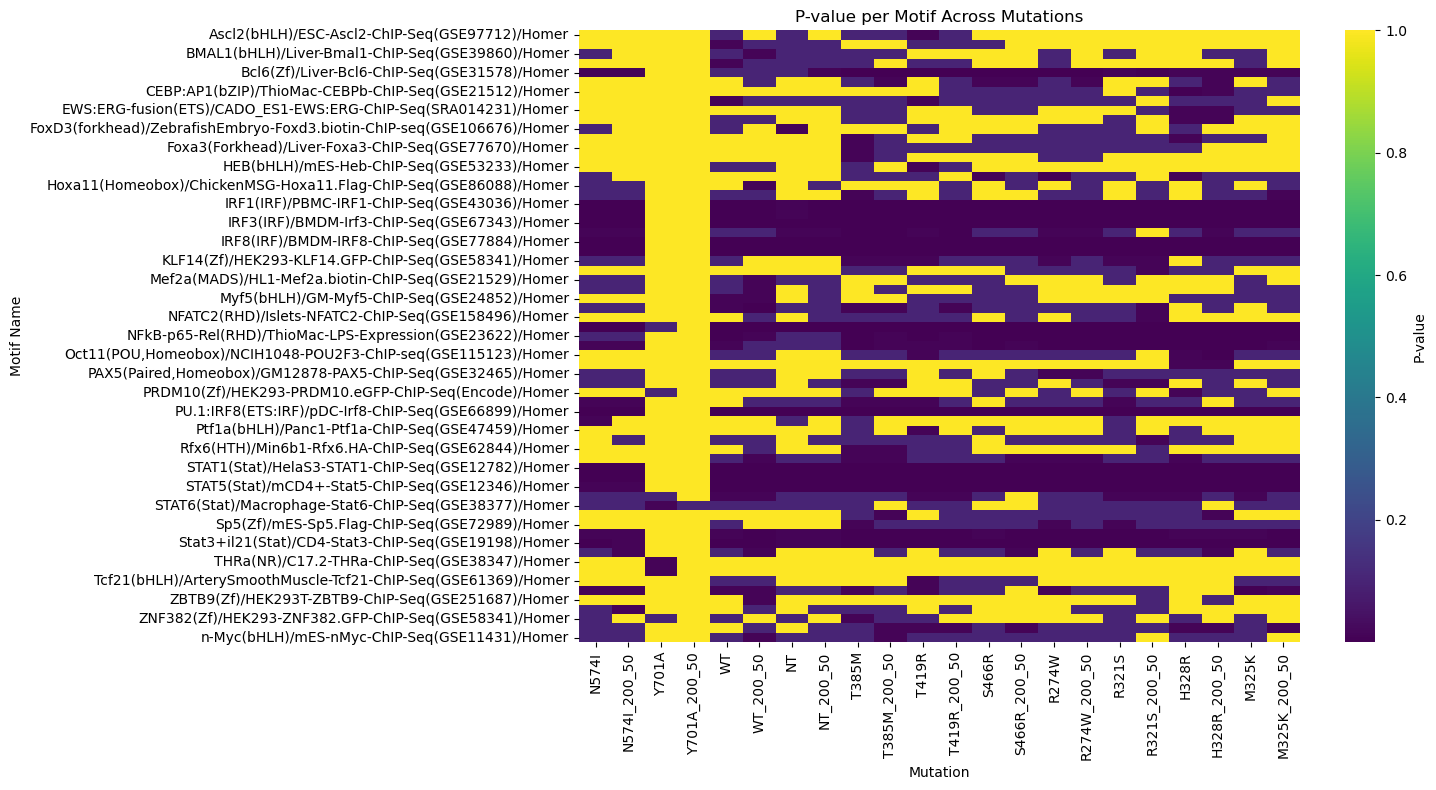

In [19]:
plt.figure(figsize=(15, 8))
sns.heatmap(df_pivot, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

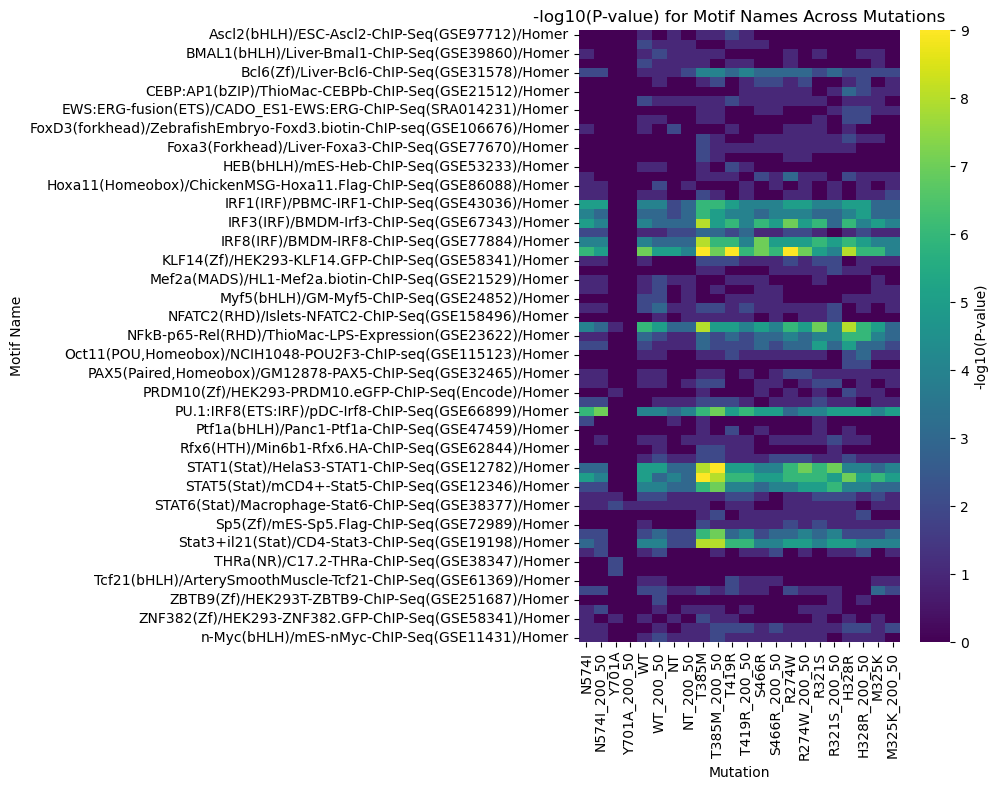

In [20]:
df_pivot_log10 = -np.log10(df_pivot)

plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_log10, cmap='viridis', cbar_kws={'label': '-log10(P-value)'})
plt.title('-log10(P-value) for Motif Names Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

In [21]:
df_pivot.columns

Index(['N574I', 'N574I_200_50', 'Y701A', 'Y701A_200_50', 'WT', 'WT_200_50',
       'NT', 'NT_200_50', 'T385M', 'T385M_200_50', 'T419R', 'T419R_200_50',
       'S466R', 'S466R_200_50', 'R274W', 'R274W_200_50', 'R321S',
       'R321S_200_50', 'H328R', 'H328R_200_50', 'M325K', 'M325K_200_50'],
      dtype='object')

In [22]:
df_pivot_bool = df_pivot.copy()
df_pivot_bool[df_pivot.columns] = np.where(df_pivot[df_pivot.columns] < 0.05, 1, 0)
df_pivot_bool.head()

,N574I,N574I_200_50,Y701A,Y701A_200_50,WT,WT_200_50,NT,NT_200_50,T385M,T385M_200_50,...,S466R,S466R_200_50,R274W,R274W_200_50,R321S,R321S_200_50,H328R,H328R_200_50,M325K,M325K_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,,
Ascl2(bHLH)/ESC-Ascl2-ChIP-Seq(GSE97712)/Homer,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Atoh1(bHLH)/Cerebellum-Atoh1-ChIP-Seq(GSE22111)/Homer,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BMAL1(bHLH)/Liver-Bmal1-ChIP-Seq(GSE39860)/Homer,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bcl11a(Zf)/HSPC-BCL11A-ChIP-Seq(GSE104676)/Homer,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,1,1,0,0,0,0,0,1,1,1,...,1,1,1,1,1,1,1,1,1,1


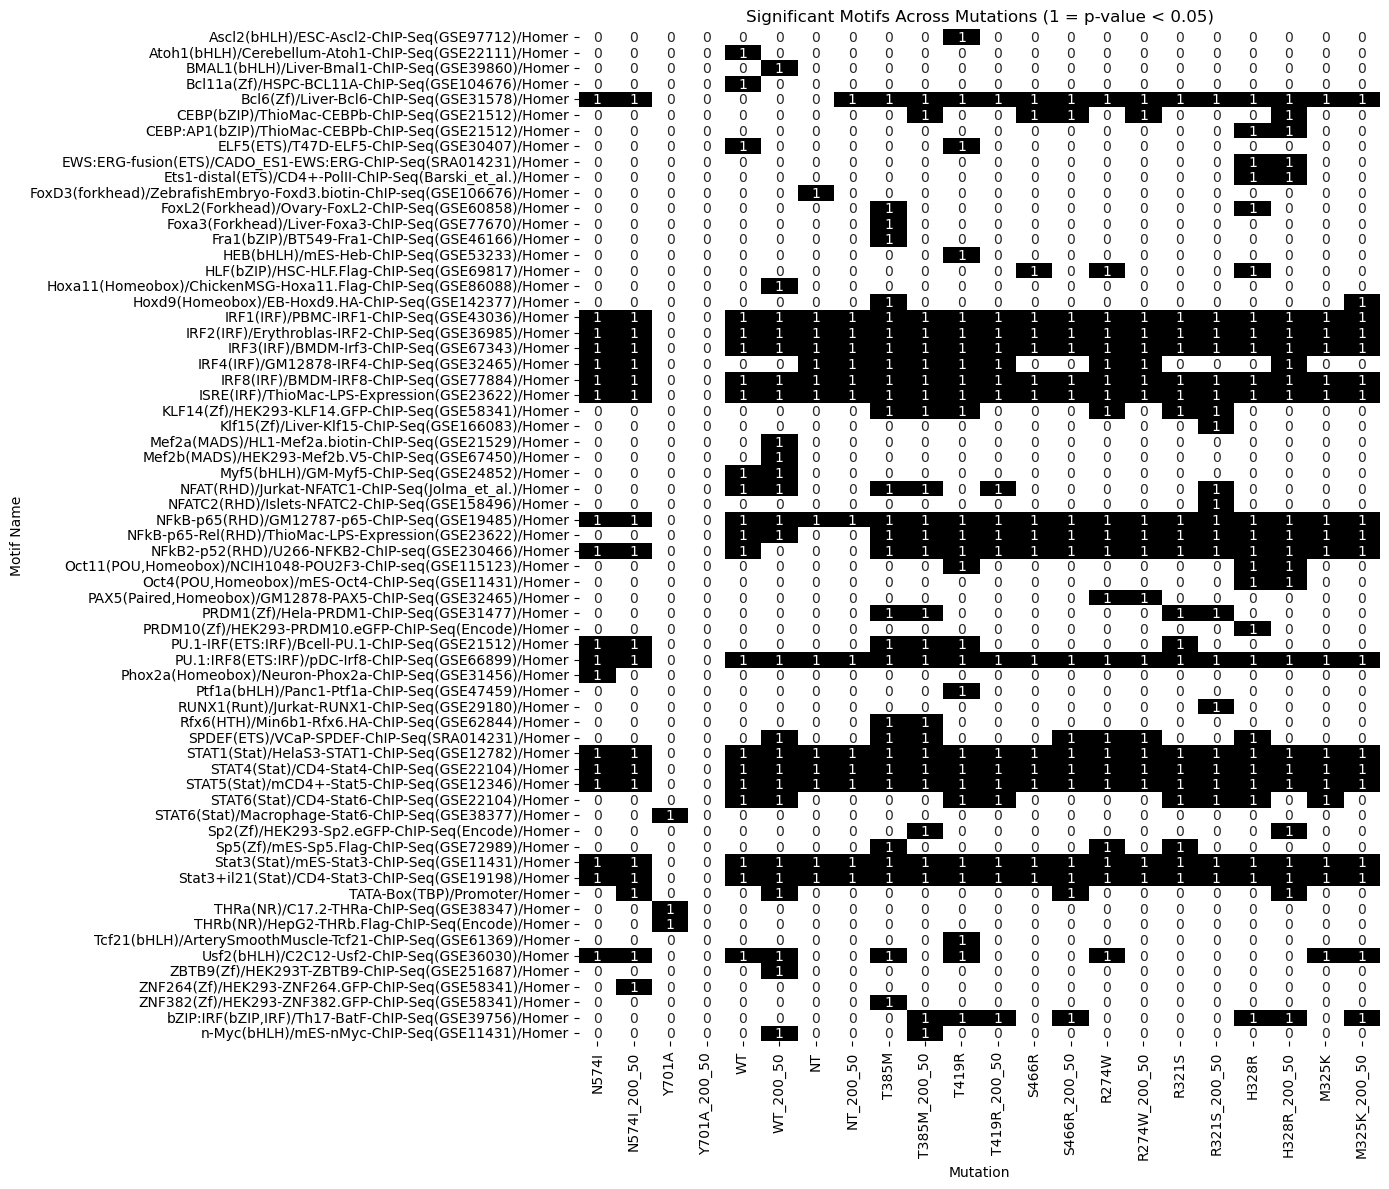

In [23]:
plt.figure(figsize=(14, 12))
sns.heatmap(df_pivot_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Filter out motifs that are significant in all mutations.

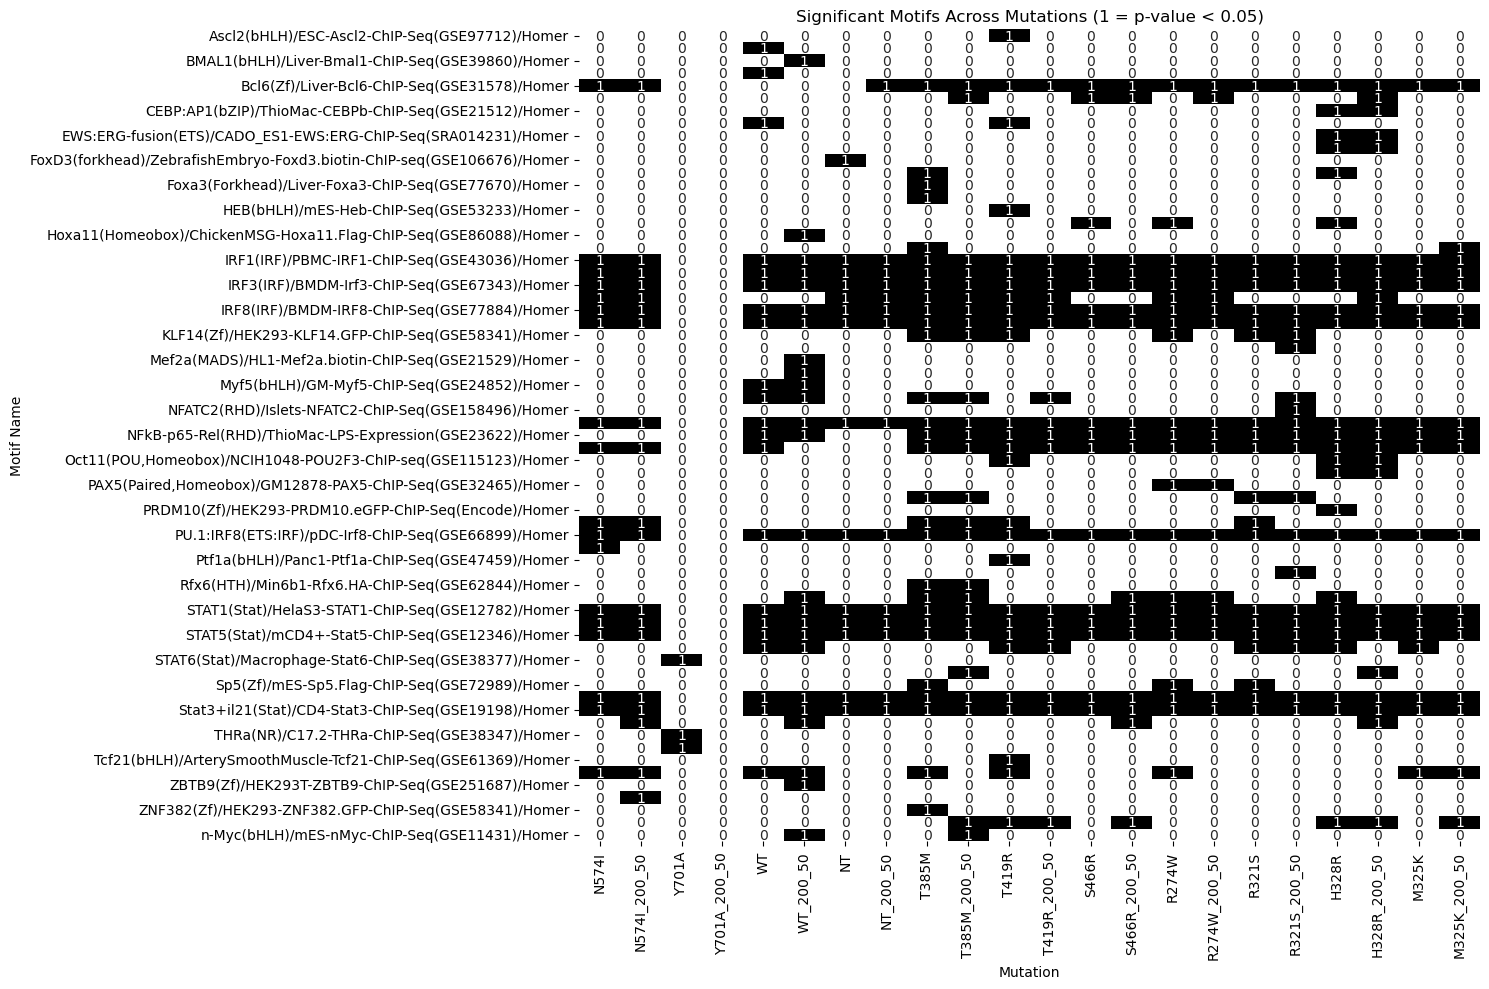

In [24]:
df_pivot_filtered = df_pivot[df_pivot[df_pivot.columns].gt(0.05).any(axis=1)]
df_pivot_bool_filtered = df_pivot_filtered.copy()
df_pivot_bool_filtered[df_pivot.columns] = np.where(df_pivot_filtered[df_pivot.columns] < 0.05, 1, 0)

plt.figure(figsize=(15, 10))
sns.heatmap(df_pivot_bool_filtered, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

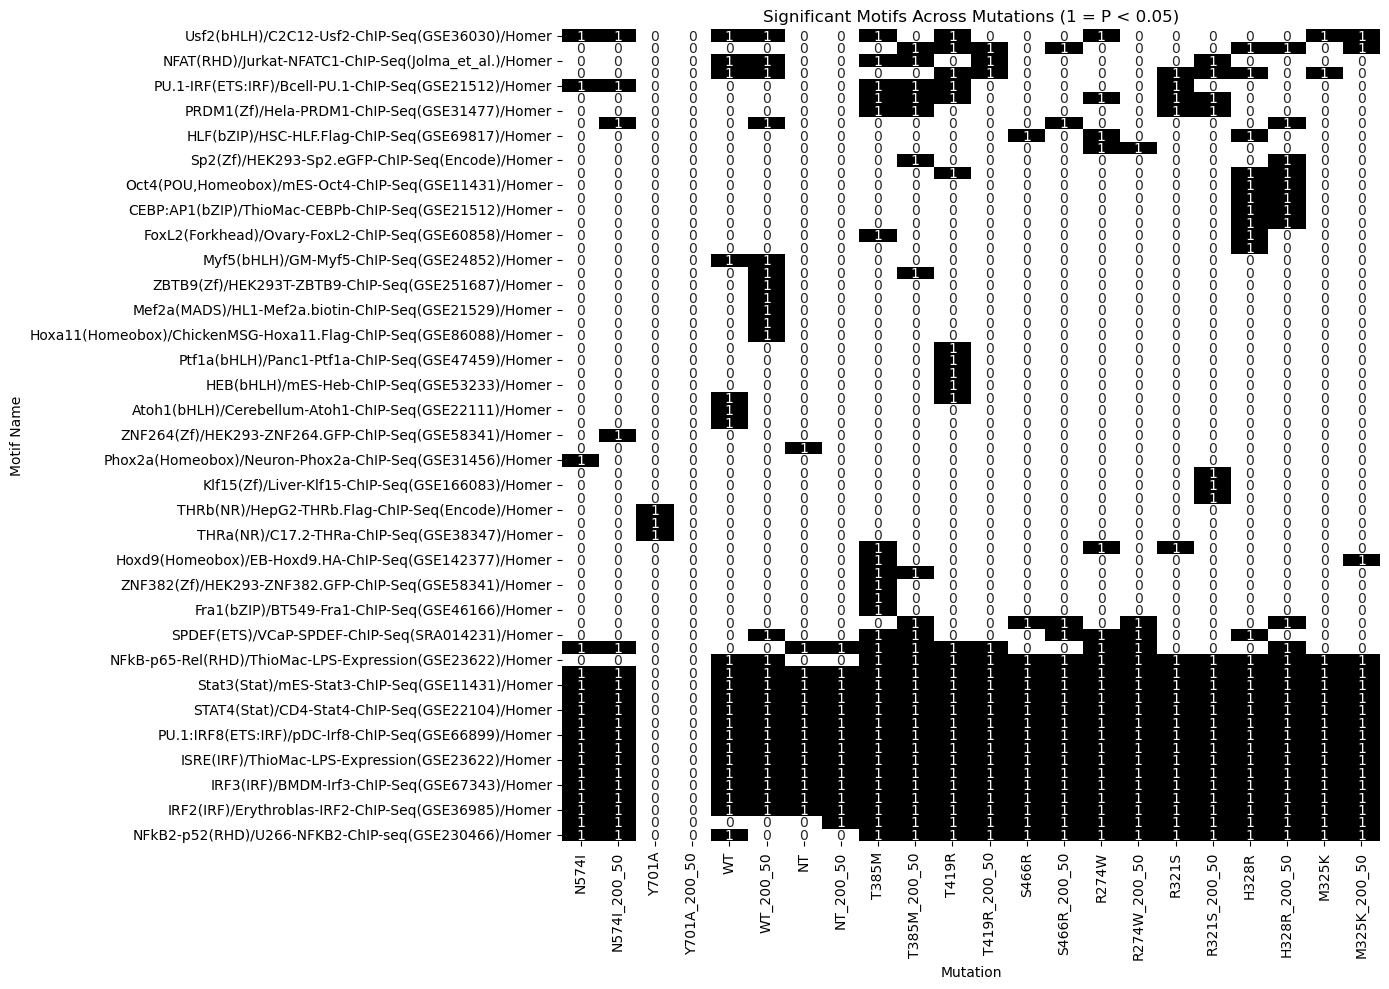

In [25]:
linkage = hierarchy.linkage(df_pivot_bool_filtered, method='average', metric='euclidean')

row_order = hierarchy.leaves_list(linkage)

df_pivot_bool_reordered = df_pivot_bool_filtered.iloc[row_order]

# Plot the heatmap with reordered rows
plt.figure(figsize=(14, 10))
sns.heatmap(df_pivot_bool_reordered,  annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = P < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

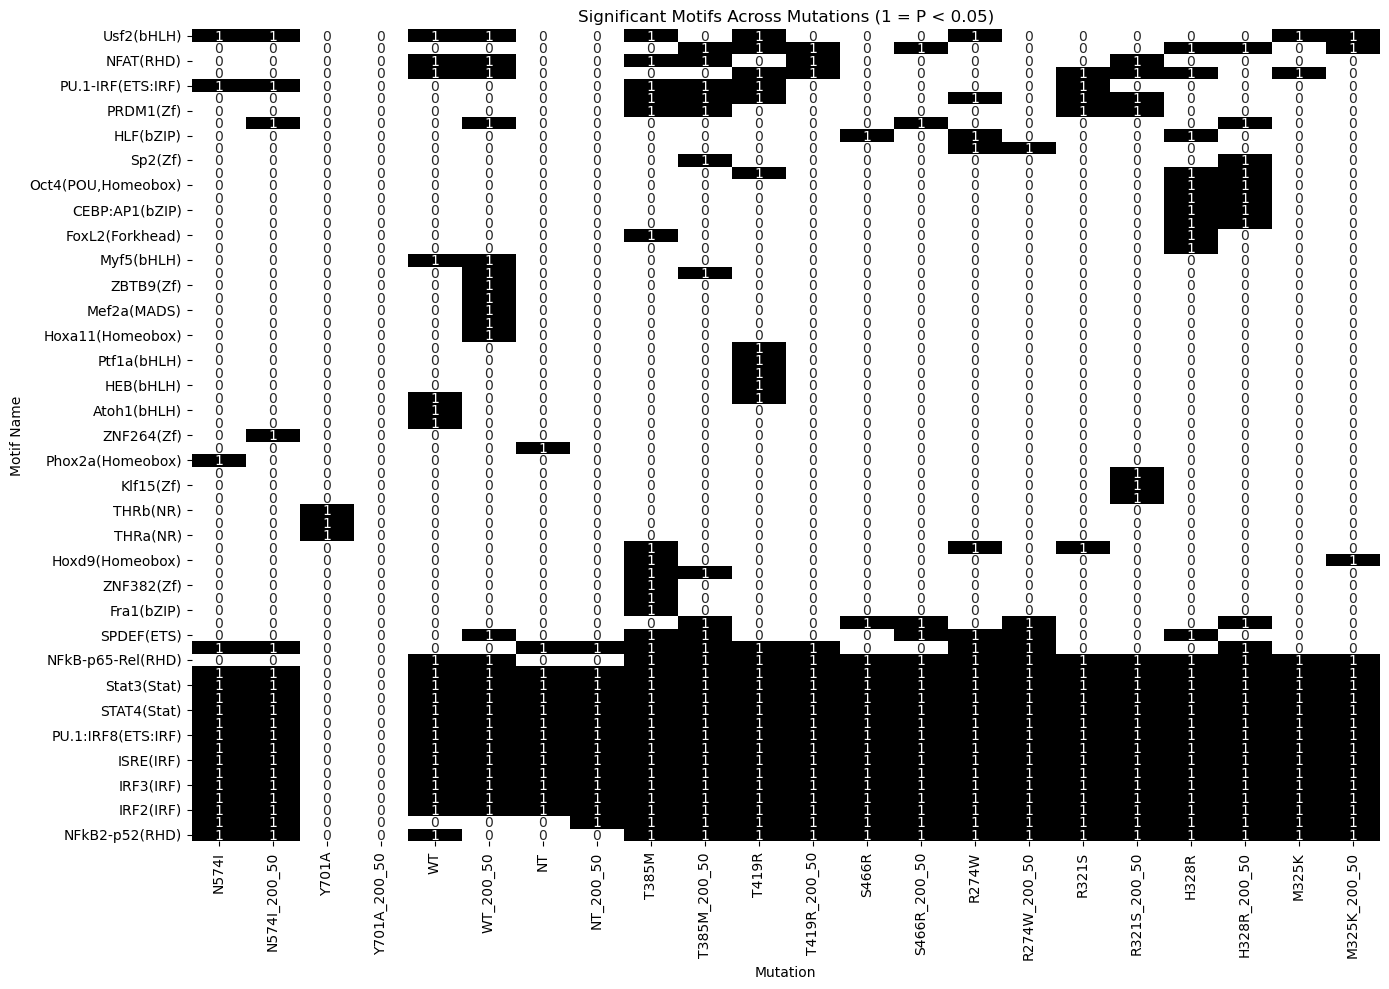

In [26]:
linkage = hierarchy.linkage(df_pivot_bool_filtered, method='average', metric='euclidean')

row_order = hierarchy.leaves_list(linkage)

df_pivot_bool_reordered = df_pivot_bool_filtered.iloc[row_order]
df_pivot_bool_reordered.index = df_pivot_bool_reordered.index.map(lambda x: x.split("/",1)[0])

# Plot the heatmap with reordered rows
plt.figure(figsize=(14, 10))
sns.heatmap(df_pivot_bool_reordered,  annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = P < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Applying hierarchical clustering order to both rows (as in the previous plot) and columns, and displaying the dendrogram.

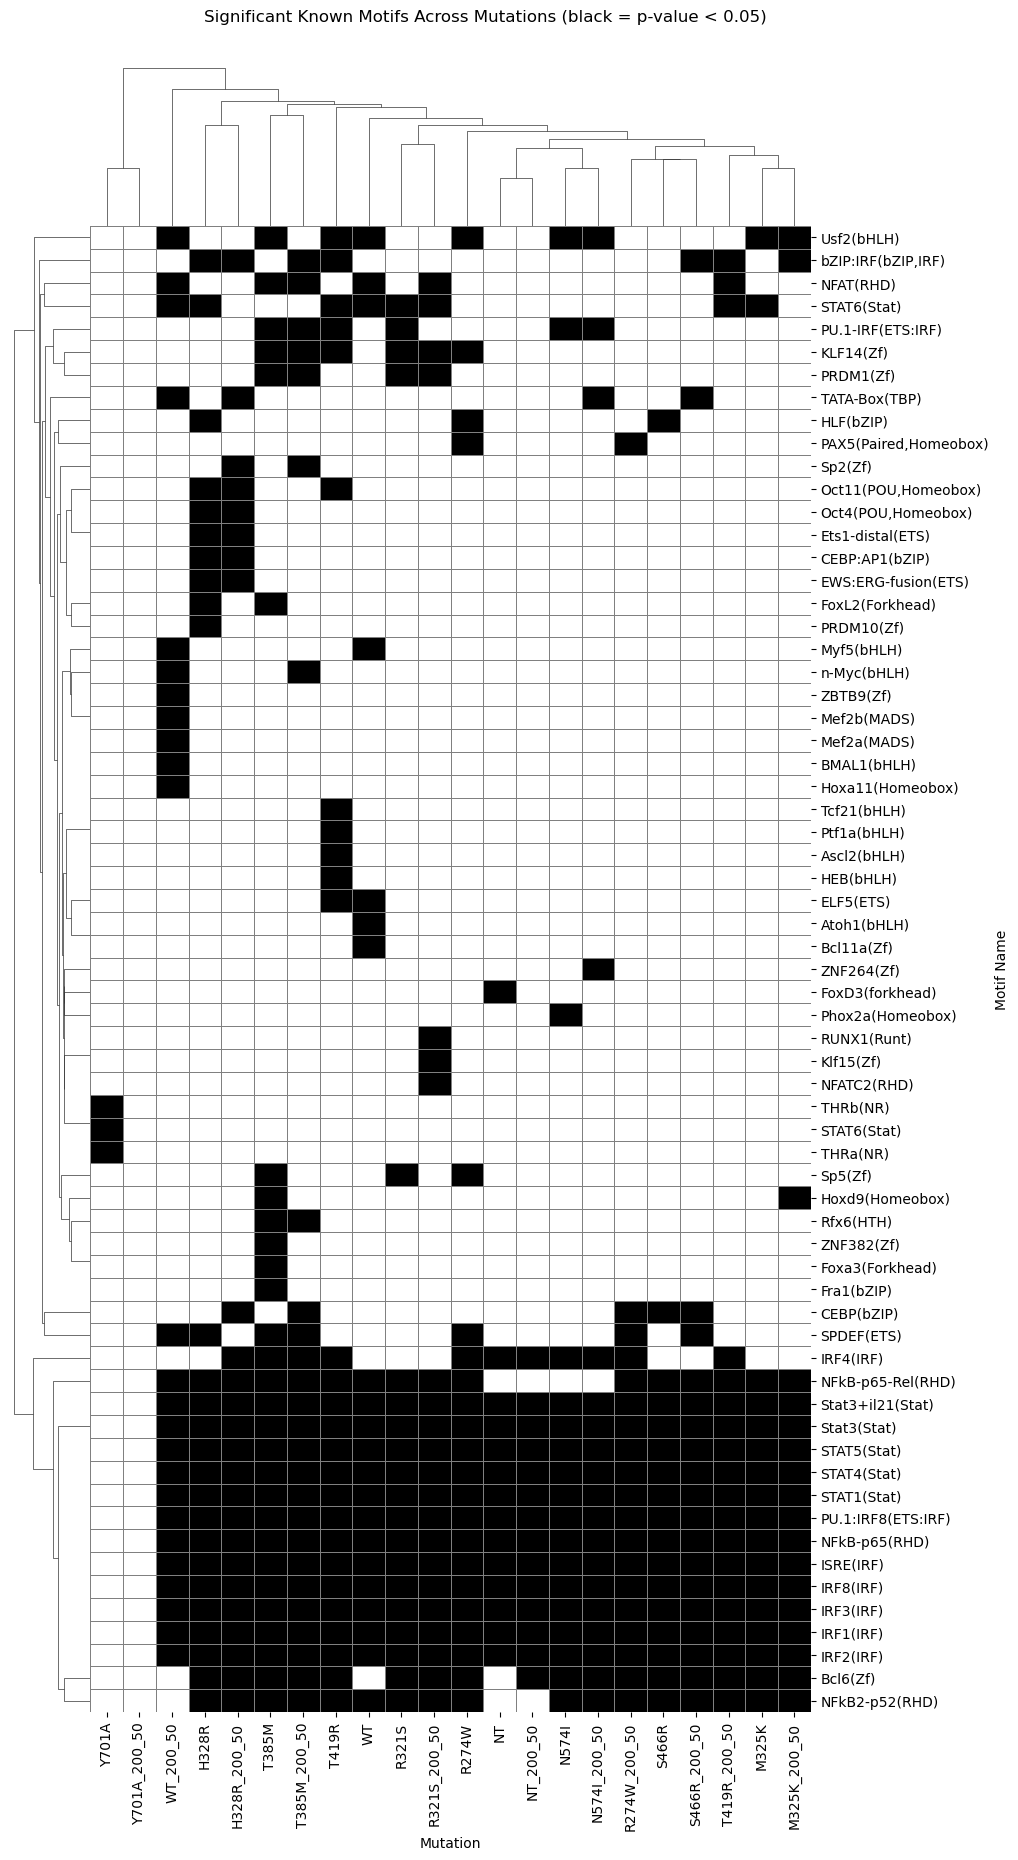

In [27]:
g = sns.clustermap(
    df_pivot_bool_filtered,
    method='average',
    metric='euclidean',
    cmap='binary',
    lw=0.5,
    linecolor="gray",
    annot=False,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(14, 18)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant Known Motifs Across Mutations (black = p-value < 0.05)', y=1.02, x=0.35)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

#### Filter by q-value

In [28]:
# Select columns: 'Motif Name' and all 'q-value' columns
qvalue_cols = [col for col in comparison.columns if col.startswith('q-value')]

df_qvalues = comparison[['Motif Name'] + qvalue_cols].copy()

In [29]:
df_qvalues

,Motif Name,q-value (Benjamini)_N574I,q-value (Benjamini)_N574I_200_50,q-value (Benjamini)_Y701A,q-value (Benjamini)_Y701A_200_50,q-value (Benjamini)_WT,q-value (Benjamini)_WT_200_50,q-value (Benjamini)_NT,q-value (Benjamini)_NT_200_50,q-value (Benjamini)_T385M,...,q-value (Benjamini)_S466R,q-value (Benjamini)_S466R_200_50,q-value (Benjamini)_R274W,q-value (Benjamini)_R274W_200_50,q-value (Benjamini)_R321S,q-value (Benjamini)_R321S_200_50,q-value (Benjamini)_H328R,q-value (Benjamini)_H328R_200_50,q-value (Benjamini)_M325K,q-value (Benjamini)_M325K_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0000,1.0000,1.0,1.0,1.0000,1.0000,1.0000,1.0,0.5231,...,0.9424,0.8061,0.9255,0.9318,0.7069,0.8373,0.9426,1.0000,1.0000,1.0000
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,1.0000,1.0000,1.0,1.0,0.9260,0.9097,1.0000,1.0,0.7578,...,1.0000,1.0000,0.9415,0.9160,1.0000,1.0000,0.9907,1.0000,1.0000,1.0000
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,0.9207,1.0000,1.0,1.0,0.9253,0.8933,1.0000,1.0,0.7649,...,1.0000,1.0000,0.7401,0.9160,0.7978,0.8398,0.5573,0.7453,1.0000,1.0000
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,0.9955,1.0000,1.0,1.0,0.9260,0.9097,1.0000,1.0,0.9323,...,0.9952,1.0000,0.8439,0.9812,0.8145,0.9022,0.6173,0.8212,1.0000,1.0000
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,1.0000,0.9634,1.0,1.0,0.9260,0.7275,0.9096,1.0,0.5941,...,0.8060,0.8079,0.8593,0.8401,0.7974,0.8373,0.9347,0.9000,0.9904,0.9548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,p53(p53)/Saos-p53-ChIP-Seq(GSE15780)/Homer,1.0000,1.0000,1.0,1.0,1.0000,1.0000,1.0000,1.0,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.6886,1.0000,1.0000,1.0000
467,p53(p53)/Saos-p53-ChIP-Seq/Homer,1.0000,1.0000,1.0,1.0,1.0000,1.0000,1.0000,1.0,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.6886,1.0000,1.0000,1.0000
468,p53(p53)/mES-cMyc-ChIP-Seq(GSE11431)/Homer,1.0000,1.0000,1.0,1.0,1.0000,1.0000,1.0000,1.0,0.7028,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
469,p63(p53)/Keratinocyte-p63-ChIP-Seq(GSE17611)/H...,1.0000,1.0000,1.0,1.0,1.0000,1.0000,1.0000,1.0,1.0000,...,1.0000,1.0000,1.0000,0.9846,1.0000,1.0000,0.9945,1.0000,1.0000,1.0000


In [30]:
# Filter for rows where any q-value column is less than or equal to 0.1
df_qvalues_filtered = df_qvalues[df_qvalues[qvalue_cols].astype(float).le(0.1).any(axis=1)]
df_qvalues_filtered.shape

(37, 23)

In [31]:
df_qvalues_filtered.columns = ['Motif Name'] + [col.replace('q-value (Benjamini)_', '') for col in df_qvalues.columns if col.startswith('q-value (Benjamini)_')]
df_qvalues_pivot = df_qvalues_filtered.set_index('Motif Name')
df_qvalues_pivot.head()

,N574I,N574I_200_50,Y701A,Y701A_200_50,WT,WT_200_50,NT,NT_200_50,T385M,T385M_200_50,...,S466R,S466R_200_50,R274W,R274W_200_50,R321S,R321S_200_50,H328R,H328R_200_50,M325K,M325K_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,,
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0.1021,0.2265,1.0,1.0,0.3757,0.2000,0.5100,0.3227,0.0036,0.0019,...,0.0169,0.0209,0.0206,0.0087,0.0321,0.0097,0.0468,0.0820,0.0397,0.0591
CEBP(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)/Homer,0.9548,0.9634,1.0,1.0,0.6984,0.2416,0.9818,0.7985,0.2780,0.0831,...,0.1907,0.0571,0.5133,0.1496,0.9281,0.7692,0.3589,0.1237,0.7436,0.5187
CEBP:AP1(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)/Homer,0.9808,0.9634,1.0,1.0,0.9662,0.7320,1.0000,1.0000,0.7810,0.5746,...,0.6155,0.7559,0.5133,0.3290,0.6715,0.4341,0.0196,0.0639,0.6614,0.4007
FoxL2(Forkhead)/Ovary-FoxL2-ChIP-Seq(GSE60858)/Homer,0.8628,1.0000,1.0,1.0,0.8571,0.8809,0.9835,1.0000,0.0570,0.2493,...,0.6943,0.7559,0.2489,0.4043,0.3901,0.7221,0.1602,0.5550,0.3834,0.8131
HLF(bZIP)/HSC-HLF.Flag-ChIP-Seq(GSE69817)/Homer,0.6548,0.9634,1.0,1.0,0.6326,0.7467,0.9878,1.0000,0.1793,0.4969,...,0.1132,0.3502,0.0293,0.3290,0.5273,0.9851,0.1361,0.3770,0.3695,0.7534


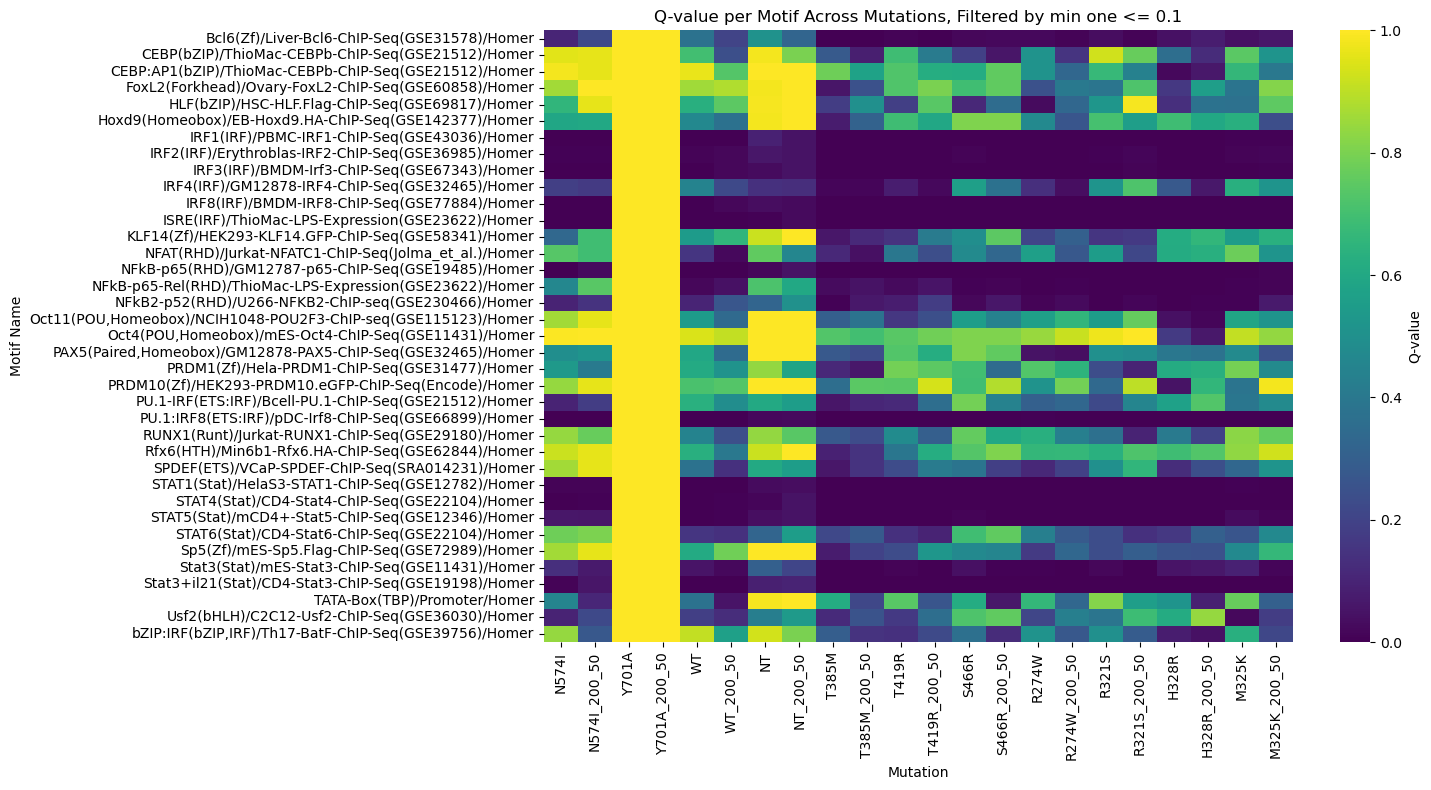

In [32]:
plt.figure(figsize=(15, 8))
sns.heatmap(df_qvalues_pivot, cmap='viridis', cbar_kws={'label': 'Q-value'})
plt.title('Q-value per Motif Across Mutations, Filtered by min one <= 0.1')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

In [33]:
df_qvalues_pivot_bool = df_qvalues_pivot.copy()
df_qvalues_pivot_bool[df_qvalues_pivot.columns] = np.where(df_qvalues_pivot[df_qvalues_pivot.columns] < 0.1, 1, 0)
df_qvalues_pivot_bool.head()

,N574I,N574I_200_50,Y701A,Y701A_200_50,WT,WT_200_50,NT,NT_200_50,T385M,T385M_200_50,...,S466R,S466R_200_50,R274W,R274W_200_50,R321S,R321S_200_50,H328R,H328R_200_50,M325K,M325K_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,,
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0,0,0,0,0,0,0,0,1,1,...,1,1,1,1,1,1,1,1,1,1
CEBP(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)/Homer,0,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
CEBP:AP1(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512)/Homer,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
FoxL2(Forkhead)/Ovary-FoxL2-ChIP-Seq(GSE60858)/Homer,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
HLF(bZIP)/HSC-HLF.Flag-ChIP-Seq(GSE69817)/Homer,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


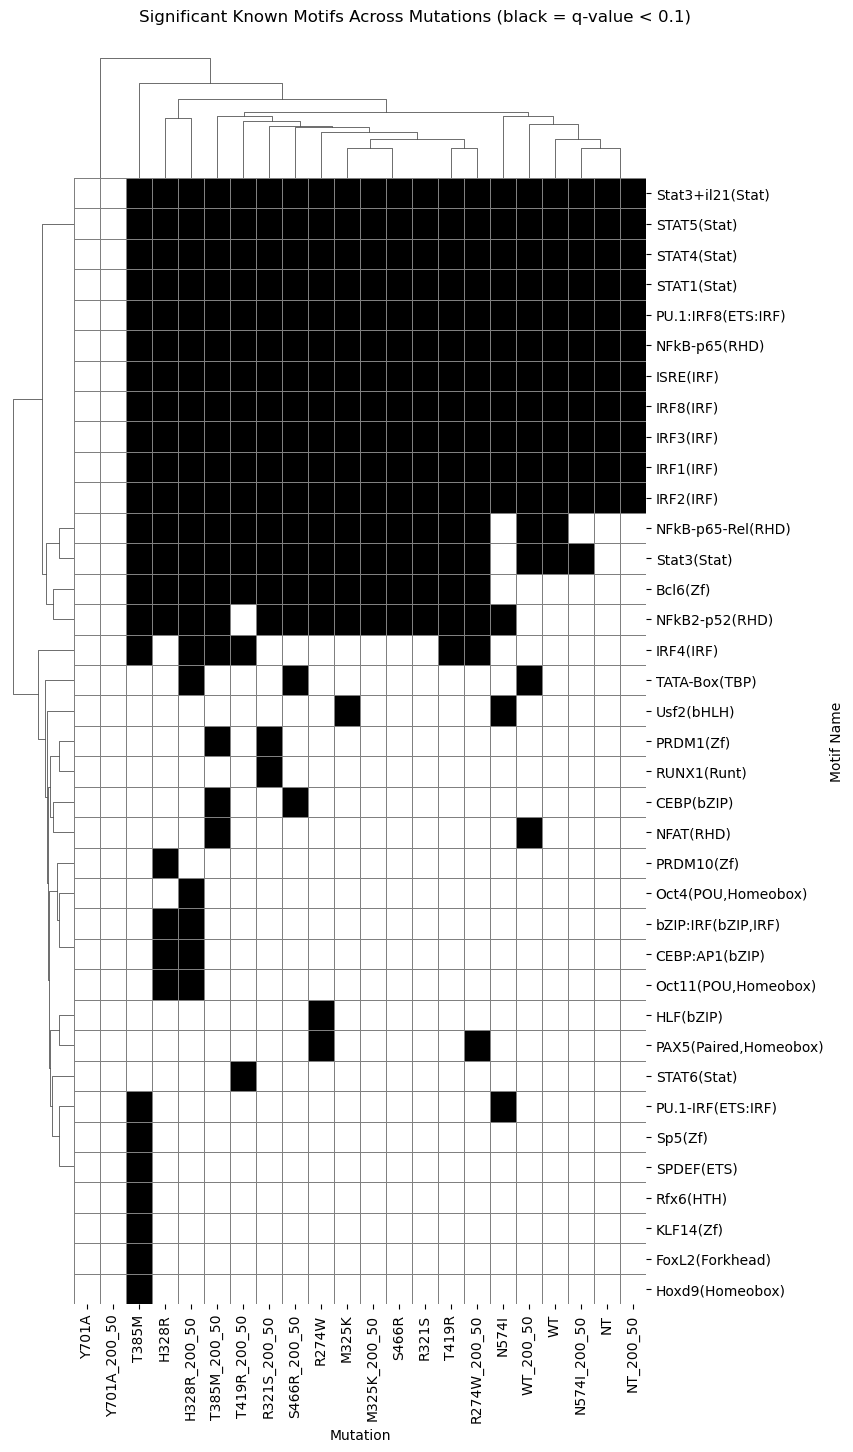

In [34]:
g = sns.clustermap(
    df_qvalues_pivot_bool,
    method='average',
    metric='euclidean',
    cmap='binary',
    lw=0.5,
    linecolor="gray",
    annot=False,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(12, 14)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant Known Motifs Across Mutations (black = q-value < 0.1)', y=1.02, x=0.35)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

#### Target gene %

In [37]:
comparison.columns

Index(['Motif Name', 'Consensus_N574I', 'P-value_N574I', 'Log P-value_N574I',
       'q-value (Benjamini)_N574I',
       '# of Target Sequences with Motif(of 104)_N574I',
       '% of Target Sequences with Motif_N574I',
       '# of Background Sequences with Motif(of 45756)',
       '% of Background Sequences with Motif_N574I', 'Consensus_N574I_200_50',
       ...
       '# of Background Sequences with Motif(of 45468)',
       '% of Background Sequences with Motif_M325K', 'Consensus_M325K_200_50',
       'P-value_M325K_200_50', 'Log P-value_M325K_200_50',
       'q-value (Benjamini)_M325K_200_50',
       '# of Target Sequences with Motif(of 101)_M325K_200_50',
       '% of Target Sequences with Motif_M325K_200_50',
       '# of Background Sequences with Motif(of 45449)',
       '% of Background Sequences with Motif_M325K_200_50'],
      dtype='object', length=177)

In [38]:
target_cols = [col for col in comparison.columns if col.startswith('% of Target Sequences with Motif_')]
df_targetpercent = comparison[['Motif Name'] + target_cols].copy()

In [39]:
df_targetpercent = df_targetpercent.map(lambda x: float(x.replace('%', '')) if isinstance(x, str) and '%' in x else x)

In [40]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50,% of Target Sequences with Motif_Y701A,% of Target Sequences with Motif_Y701A_200_50,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_WT_200_50,% of Target Sequences with Motif_NT,% of Target Sequences with Motif_NT_200_50,% of Target Sequences with Motif_T385M,...,% of Target Sequences with Motif_S466R,% of Target Sequences with Motif_S466R_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_H328R,% of Target Sequences with Motif_H328R_200_50,% of Target Sequences with Motif_M325K,% of Target Sequences with Motif_M325K_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,17.31,11.54,20.0,0.0,16.84,12.63,17.07,9.76,25.00,...,22.70,19.15,21.95,16.46,24.53,18.24,20.93,15.12,19.80,13.86
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,4.81,2.88,0.0,0.0,8.42,6.32,7.32,4.88,8.33,...,5.67,4.96,7.32,6.10,6.29,4.40,6.40,4.65,5.94,3.96
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,22.12,16.35,0.0,0.0,20.00,15.79,21.95,21.95,19.79,...,17.02,12.77,20.73,15.24,22.01,17.61,23.26,16.86,19.80,13.86
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,25.96,21.15,20.0,20.0,25.26,20.00,29.27,26.83,23.44,...,22.70,17.02,25.00,18.29,27.67,22.01,27.91,20.93,25.74,18.81
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,42.31,35.58,40.0,20.0,45.26,37.89,51.22,39.02,46.88,...,47.52,36.88,44.51,35.37,45.91,35.85,43.02,33.72,44.55,34.65


In [41]:
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].map(lambda x: x.split("/")[:1])
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].apply(lambda x: "/".join(map(str, x)))

In [42]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50,% of Target Sequences with Motif_Y701A,% of Target Sequences with Motif_Y701A_200_50,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_WT_200_50,% of Target Sequences with Motif_NT,% of Target Sequences with Motif_NT_200_50,% of Target Sequences with Motif_T385M,...,% of Target Sequences with Motif_S466R,% of Target Sequences with Motif_S466R_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_H328R,% of Target Sequences with Motif_H328R_200_50,% of Target Sequences with Motif_M325K,% of Target Sequences with Motif_M325K_200_50
0,AMYB(HTH),17.31,11.54,20.0,0.0,16.84,12.63,17.07,9.76,25.00,...,22.70,19.15,21.95,16.46,24.53,18.24,20.93,15.12,19.80,13.86
1,AP-1(bZIP),4.81,2.88,0.0,0.0,8.42,6.32,7.32,4.88,8.33,...,5.67,4.96,7.32,6.10,6.29,4.40,6.40,4.65,5.94,3.96
2,AP-2alpha(AP2),22.12,16.35,0.0,0.0,20.00,15.79,21.95,21.95,19.79,...,17.02,12.77,20.73,15.24,22.01,17.61,23.26,16.86,19.80,13.86
3,AP-2gamma(AP2),25.96,21.15,20.0,20.0,25.26,20.00,29.27,26.83,23.44,...,22.70,17.02,25.00,18.29,27.67,22.01,27.91,20.93,25.74,18.81
4,AR-halfsite(NR),42.31,35.58,40.0,20.0,45.26,37.89,51.22,39.02,46.88,...,47.52,36.88,44.51,35.37,45.91,35.85,43.02,33.72,44.55,34.65


In [43]:
# Extract mutation names from column names
df_targetpercent.columns = ['Motif Name'] + [col.replace('% of Target Sequences with Motif_', '') for col in df_targetpercent.columns if col.startswith('% of Target Sequences with Motif_')]
df_target_pivot = df_targetpercent.set_index('Motif Name')
df_target_pivot.head()

,N574I,N574I_200_50,Y701A,Y701A_200_50,WT,WT_200_50,NT,NT_200_50,T385M,T385M_200_50,...,S466R,S466R_200_50,R274W,R274W_200_50,R321S,R321S_200_50,H328R,H328R_200_50,M325K,M325K_200_50
Motif Name,,,,,,,,,,,,,,,,,,,,,
AMYB(HTH),17.31,11.54,20.0,0.0,16.84,12.63,17.07,9.76,25.00,19.27,...,22.70,19.15,21.95,16.46,24.53,18.24,20.93,15.12,19.80,13.86
AP-1(bZIP),4.81,2.88,0.0,0.0,8.42,6.32,7.32,4.88,8.33,6.25,...,5.67,4.96,7.32,6.10,6.29,4.40,6.40,4.65,5.94,3.96
AP-2alpha(AP2),22.12,16.35,0.0,0.0,20.00,15.79,21.95,21.95,19.79,15.62,...,17.02,12.77,20.73,15.24,22.01,17.61,23.26,16.86,19.80,13.86
AP-2gamma(AP2),25.96,21.15,20.0,20.0,25.26,20.00,29.27,26.83,23.44,18.23,...,22.70,17.02,25.00,18.29,27.67,22.01,27.91,20.93,25.74,18.81
AR-halfsite(NR),42.31,35.58,40.0,20.0,45.26,37.89,51.22,39.02,46.88,36.46,...,47.52,36.88,44.51,35.37,45.91,35.85,43.02,33.72,44.55,34.65


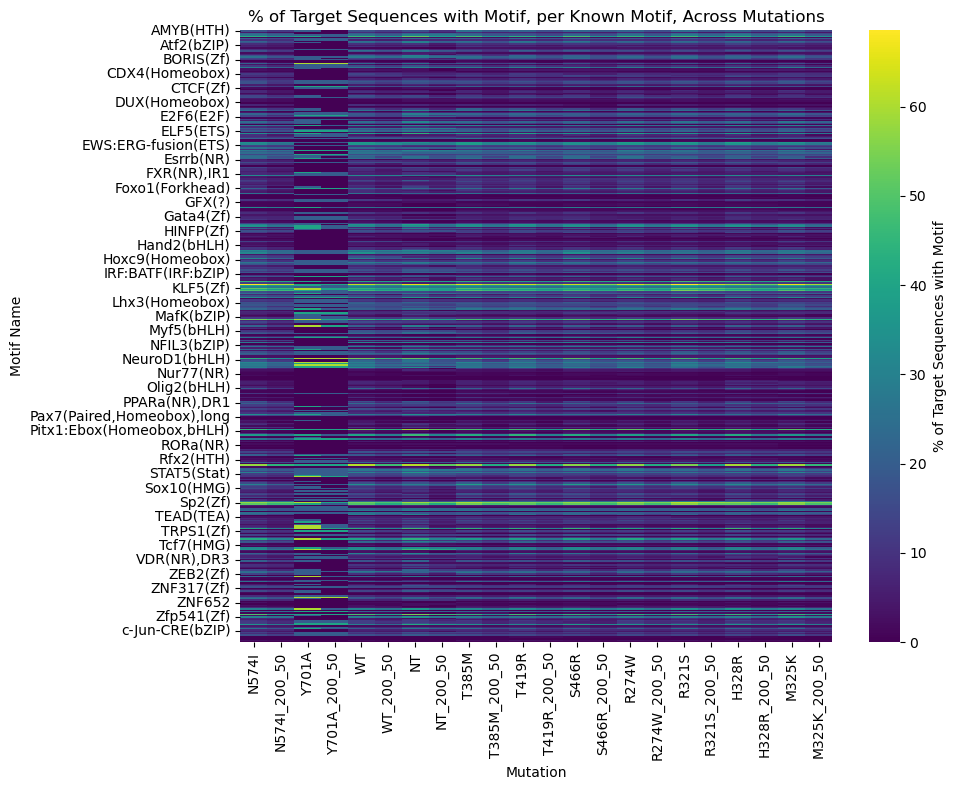

In [44]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_target_pivot, cmap='viridis', cbar_kws={'label': '% of Target Sequences with Motif'})
plt.title('% of Target Sequences with Motif, per Known Motif, Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

/home/irati/miniconda3/envs/thesis_omics/lib/python3.13/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/irati/miniconda3/envs/thesis_omics/lib/python3.13/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)




In [45]:
n_motifs = df_target_pivot.shape[0]
height_per_motif = 0.25 
fig_height = max(8, n_motifs * height_per_motif)  # min height 8
fig_width = 10

g = sns.clustermap(
    df_target_pivot,
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(0.90, 0.05, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(fig_width, fig_height)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

**Filter by motifs with significant differences across mutations**

Show only the motifs that, as a result of the previous analysis, were found to be significant in some mutations and non-significant in others.

In [46]:
motifs_sig = df_pivot_bool_filtered.index

In [47]:
len(motifs_sig)

65

There are 65 motifs meeting this criteria.

Shorten the motif names.

In [48]:
motifs_sig = motifs_sig.map(lambda x: x.split("/",1)[0])

In [49]:
motifs_sig

Index(['Ascl2(bHLH)', 'Atoh1(bHLH)', 'BMAL1(bHLH)', 'Bcl11a(Zf)', 'Bcl6(Zf)',
       'CEBP(bZIP)', 'CEBP:AP1(bZIP)', 'ELF5(ETS)', 'EWS:ERG-fusion(ETS)',
       'Ets1-distal(ETS)', 'FoxD3(forkhead)', 'FoxL2(Forkhead)',
       'Foxa3(Forkhead)', 'Fra1(bZIP)', 'HEB(bHLH)', 'HLF(bZIP)',
       'Hoxa11(Homeobox)', 'Hoxd9(Homeobox)', 'IRF1(IRF)', 'IRF2(IRF)',
       'IRF3(IRF)', 'IRF4(IRF)', 'IRF8(IRF)', 'ISRE(IRF)', 'KLF14(Zf)',
       'Klf15(Zf)', 'Mef2a(MADS)', 'Mef2b(MADS)', 'Myf5(bHLH)', 'NFAT(RHD)',
       'NFATC2(RHD)', 'NFkB-p65(RHD)', 'NFkB-p65-Rel(RHD)', 'NFkB2-p52(RHD)',
       'Oct11(POU,Homeobox)', 'Oct4(POU,Homeobox)', 'PAX5(Paired,Homeobox)',
       'PRDM1(Zf)', 'PRDM10(Zf)', 'PU.1-IRF(ETS:IRF)', 'PU.1:IRF8(ETS:IRF)',
       'Phox2a(Homeobox)', 'Ptf1a(bHLH)', 'RUNX1(Runt)', 'Rfx6(HTH)',
       'SPDEF(ETS)', 'STAT1(Stat)', 'STAT4(Stat)', 'STAT5(Stat)',
       'STAT6(Stat)', 'STAT6(Stat)', 'Sp2(Zf)', 'Sp5(Zf)', 'Stat3(Stat)',
       'Stat3+il21(Stat)', 'TATA-Box(TBP)', 'THRa(NR)

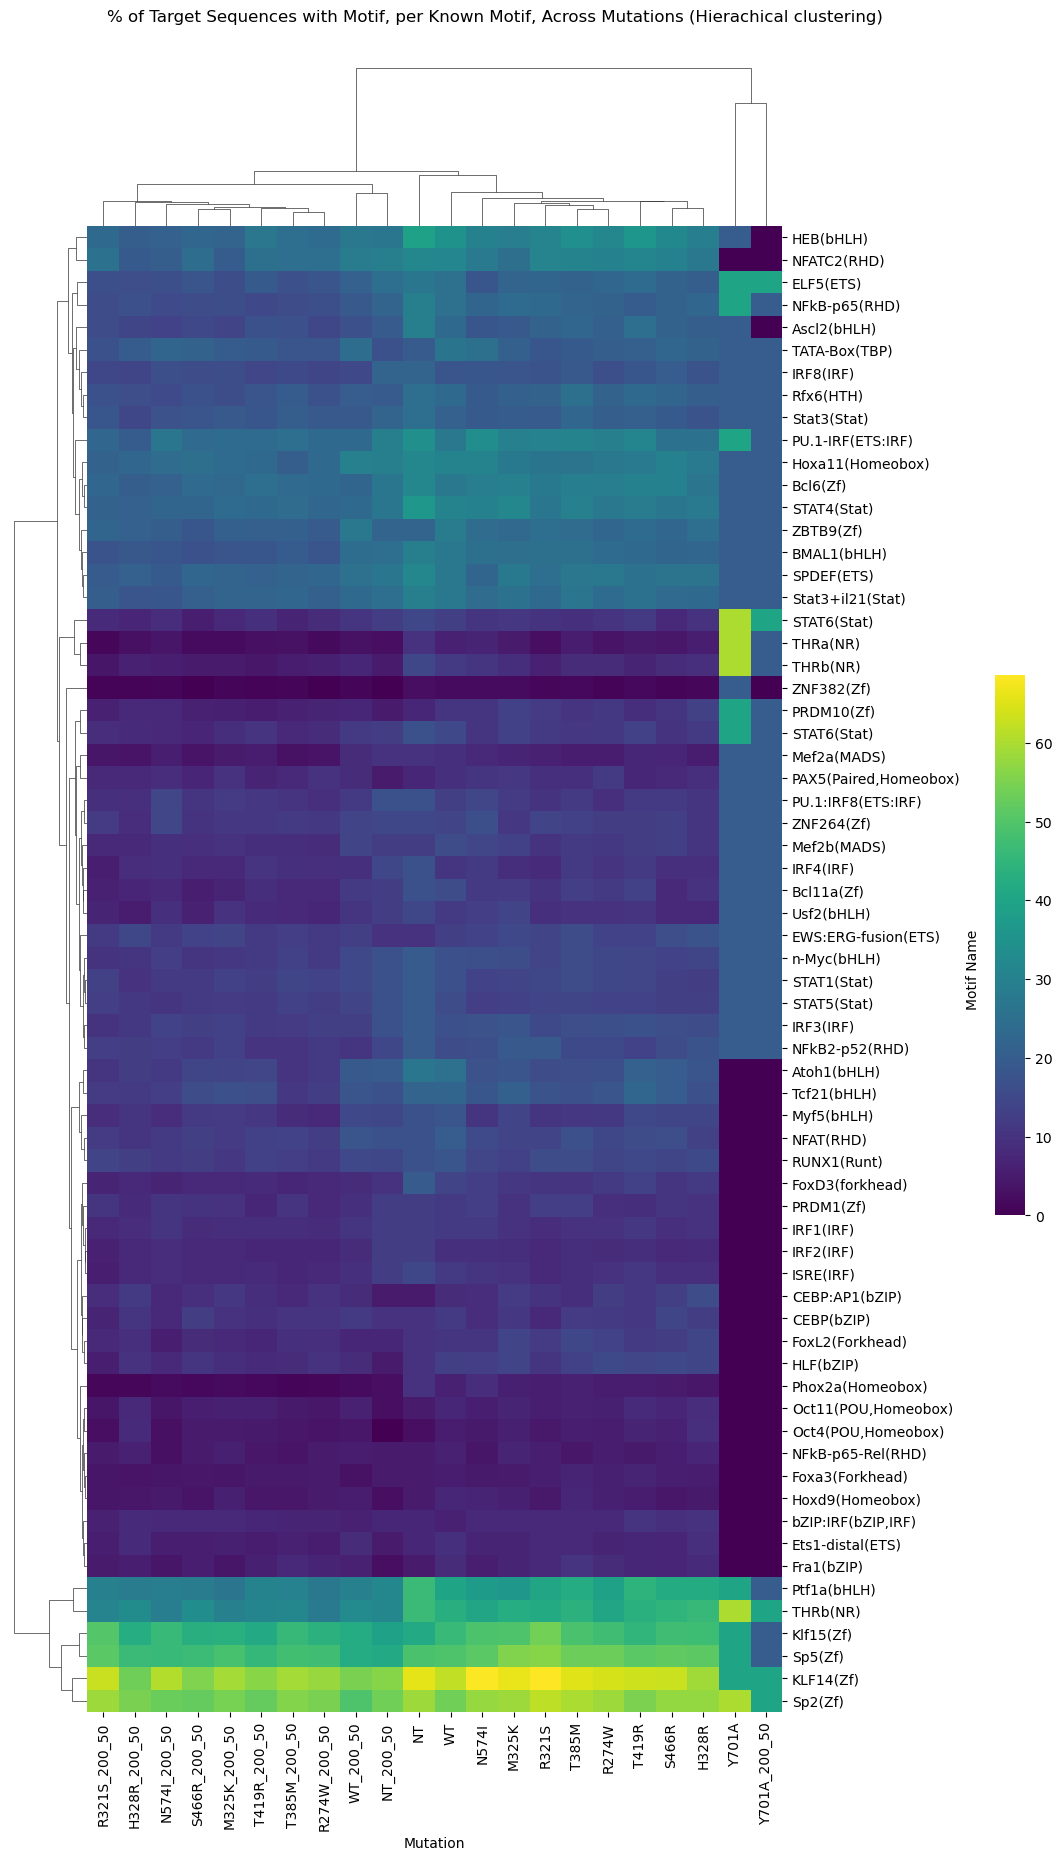

In [50]:
g = sns.clustermap(
    df_target_pivot[df_target_pivot.index.isin(motifs_sig)],
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(1, 0.35, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(10, 18)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

### De novo significant motifs

HOMER seems to mark as "possible false possitive" the de novo motifs with p-value <= 1e-11.

In [35]:
def parse_denovo_motifs(file_path):
    # Initialize lists to store parsed data
    data = {
        'Consensus': [],
        'Motif_Name': [],
        'Best_Guess': [],
        'Score': [],
        'Log_Pvalue': [],
        'Qvalue': [],
        'Target_Percent': [],
        'Background_Percent': [],
        'Pvalue': []
    }
    
    # Read the file
    with open(file_path, 'r') as f:
        for line in f:
            if line.startswith('>'):
                # Split the header line
                parts = line.strip().split('\t')
                if len(parts) < 6:
                    continue  # Skip malformed lines
                
                # Extract fields
                consensus = parts[0][1:]  # Remove '>'
                motif_info = parts[1].split(',')
                motif_name = motif_info[0]
                best_guess = motif_info[1].replace("BestGuess:", "") if len(motif_info) > 1 else 'Unknown'
                score = float(parts[2])
                log_pvalue = float(parts[3])
                qvalue = float(parts[4])
                
                # Parse target and background stats
                stats = parts[5].split(',')
                target_info = stats[0].split(':')[1].split('(')
                target_count = float(target_info[0])
                target_percent = float(target_info[1].rstrip('%)'))
                bg_info = stats[1].split(':')[1].split('(')
                bg_count = float(bg_info[0])
                bg_percent = float(bg_info[1].rstrip('%)'))
                pvalue = parts[5].split('P:')[1]
                
                # Append to data
                data['Consensus'].append(consensus)
                data['Motif_Name'].append(motif_name)
                data['Best_Guess'].append(best_guess)
                data['Score'].append(score)
                data['Log_Pvalue'].append(log_pvalue)
                data['Qvalue'].append(qvalue)
                data['Target_Percent'].append(target_percent)
                data['Background_Percent'].append(bg_percent)
                data['Pvalue'].append(pvalue)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [36]:
novo_motif_dfs = {}

for col in cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    novo_motif_dfs[key_motifs] = parse_denovo_motifs(f"up_IFNg/up_{col}/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    novo_motif_dfs[key_motifs_200_50] = parse_denovo_motifs(f"up_IFNg/up_{col}_200_50/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs_200_50].shape)

N574I_motifs
(40, 9)
N574I_motifs_200_50
(26, 9)
Y701A_motifs
(74, 9)
Y701A_motifs_200_50
(70, 9)
WT_motifs
(32, 9)
WT_motifs_200_50
(22, 9)
NT_motifs
(18, 9)
NT_motifs_200_50
(14, 9)
T385M_motifs
(46, 9)
T385M_motifs_200_50
(34, 9)
T419R_motifs
(34, 9)
T419R_motifs_200_50
(30, 9)
S466R_motifs
(36, 9)
S466R_motifs_200_50
(26, 9)
R274W_motifs
(46, 9)
R274W_motifs_200_50
(22, 9)
R321S_motifs
(40, 9)
R321S_motifs_200_50
(28, 9)
H328R_motifs
(40, 9)
H328R_motifs_200_50
(36, 9)
M325K_motifs
(30, 9)
M325K_motifs_200_50
(24, 9)


In [37]:
novo_motif_dfs["WT_motifs"].head()


,Consensus,Motif_Name,Best_Guess,Score,Log_Pvalue,Qvalue,Target_Percent,Background_Percent,Pvalue
0,TTCCTGGAAATC,1-TTCCTGGAAATC,STAT1(Stat)/HelaS3-STAT1-ChIP-Seq(GSE12782)/Ho...,10.614751,-23.929869,0.0,11.58,0.64,1e-10
1,CTCTCGGTTC,1-CTCTCGGTTC,PB0140.1_Irf6_2/Jaspar(0.747),10.352391,-23.481966,0.0,11.58,0.67,1e-10
2,AATGAGCCAA,2-AATGAGCCAA,Jun/MA0489.3/Jaspar(0.698),10.355632,-23.348096,0.0,11.58,0.67,1e-10
3,VCTTTCAGTTTC,2-VCTTTCAGTTTC,IRF2(IRF)/Erythroblas-IRF2-ChIP-Seq(GSE36985)/...,10.084474,-23.149179,0.0,9.47,0.35,1e-10
4,TCATCCAATTAG,3-TCATCCAATTAG,PH0089.1_Isx/Jaspar(0.745),14.995138,-22.087885,0.0,4.21,0.00,1e-9


In [38]:
df_pivot.columns

Index(['N574I', 'N574I_200_50', 'Y701A', 'Y701A_200_50', 'WT', 'WT_200_50',
       'NT', 'NT_200_50', 'T385M', 'T385M_200_50', 'T419R', 'T419R_200_50',
       'S466R', 'S466R_200_50', 'R274W', 'R274W_200_50', 'R321S',
       'R321S_200_50', 'H328R', 'H328R_200_50', 'M325K', 'M325K_200_50'],
      dtype='object')

In [39]:
# Initialize an empty list to collect data
motif_pvalues = []

# Get unique motifs and collect P-values
for df_name in novo_motif_dfs.keys():
    # Convert Pvalue to numeric
    novo_motif_dfs[df_name]["Pvalue"] = pd.to_numeric(novo_motif_dfs[df_name]["Pvalue"])
    # Ensure the column contains only strings before applying .str
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].str.split("/").str[:2]
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].apply(lambda x: "/".join(map(str, x)))
    
    # Filter for significant motifs (P-value < 1e-11)
    filtered_df = novo_motif_dfs[df_name][["Best_Guess", "Pvalue"]].drop_duplicates()
    # Rename Pvalue column to the DataFrame name
    filtered_df = filtered_df.rename(columns={"Pvalue": df_name})
    filtered_df.columns = filtered_df.columns.str.replace('_motifs', '')
    
    # Append to list
    motif_pvalues.append(filtered_df)

# Merge all DataFrames on Best_Guess using outer join
denovo_sig = motif_pvalues[0]
for df in motif_pvalues[1:]:
    denovo_sig = denovo_sig.merge(df, on="Best_Guess", how="outer")

# Set Best_Guess as index
denovo_sig = denovo_sig.set_index("Best_Guess")

denovo_sig.shape



(223, 22)

In [40]:
denovo_sig.head(20)

,N574I,N574I_200_50,Y701A,Y701A_200_50,WT,WT_200_50,NT,NT_200_50,T385M,T385M_200_50,...,S466R,S466R_200_50,R274W,R274W_200_50,R321S,R321S_200_50,H328R,H328R_200_50,M325K,M325K_200_50
Best_Guess,,,,,,,,,,,,,,,,,,,,,
AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.000000e-07,NaN,NaN,NaN,NaN
Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.),NaN,NaN,NaN,0.0001,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Atoh1/MA1467.3,NaN,NaN,NaN,0.0001,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-16,1.000000e-14,...,NaN,1.000000e-08,NaN,1.000000e-11,NaN,NaN,NaN,NaN,NaN,NaN
Brn2(POU,1.000000e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CArG(MADS)/PUER-Srf-ChIP-Seq(Sullivan_et_al.),NaN,1.000000e-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CEBPG/MA0838.1,NaN,NaN,0.001,0.0001,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
COUP-TFII(NR)/Artia-Nr2f2-ChIP-Seq(GSE46497),NaN,NaN,0.001,0.0001,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CTCFL/MA1102.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e-07,NaN,...,NaN,NaN,1.000000e-09,1.000000e-09,1.000000e-08,NaN,NaN,NaN,NaN,NaN


In [41]:
denovo_sig['N574I'].head(20)

Best_Guess
AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477)                      NaN
Arnt:Ahr(bHLH)/MCF7-Arnt-ChIP-Seq(Lo_et_al.)                         NaN
Atoh1/MA1467.3                                                       NaN
Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)                               NaN
Brn2(POU                                                    1.000000e-03
CArG(MADS)/PUER-Srf-ChIP-Seq(Sullivan_et_al.)                        NaN
CEBPG/MA0838.1                                                       NaN
COUP-TFII(NR)/Artia-Nr2f2-ChIP-Seq(GSE46497)                         NaN
CTCFL/MA1102.3                                                       NaN
DMRT3/MA0610.2                                                       NaN
Dlx2/MA0885.3                                                        NaN
E2F4(E2F)/K562-E2F4-ChIP-Seq(GSE31477)                               NaN
EPAS1/MA2325.1                                                       NaN
ETS:E-box(ETS                           

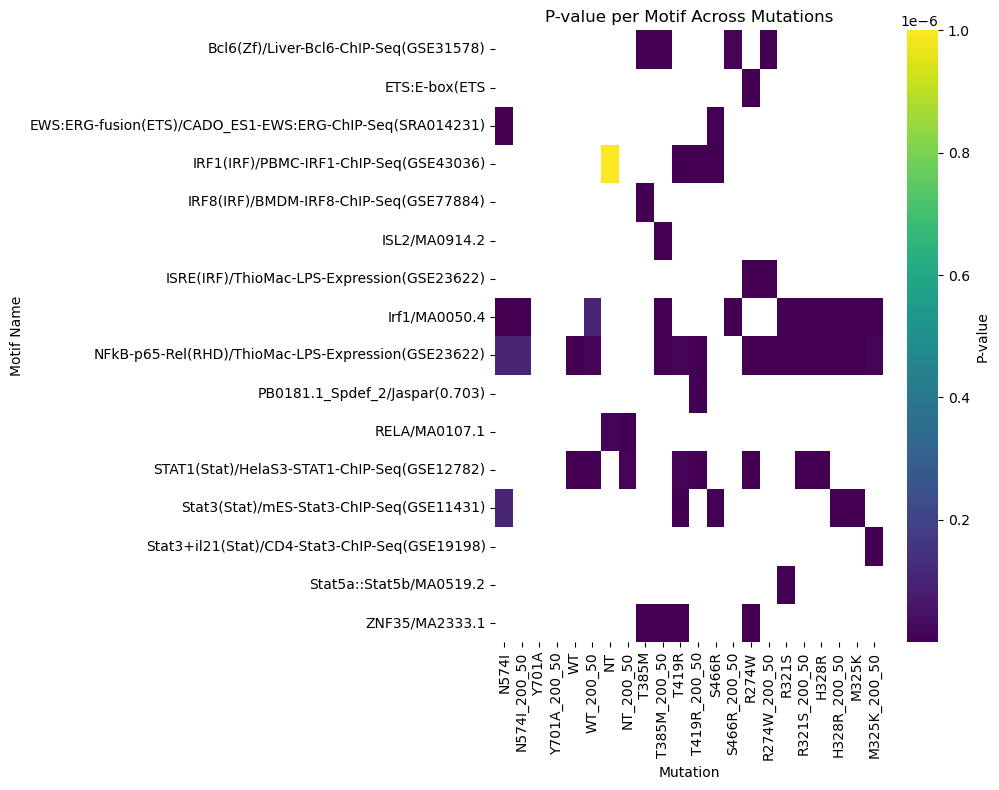

In [42]:
denovo_sig_filtered = denovo_sig[denovo_sig[denovo_sig.columns].le(1e-11).any(axis=1)]


plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

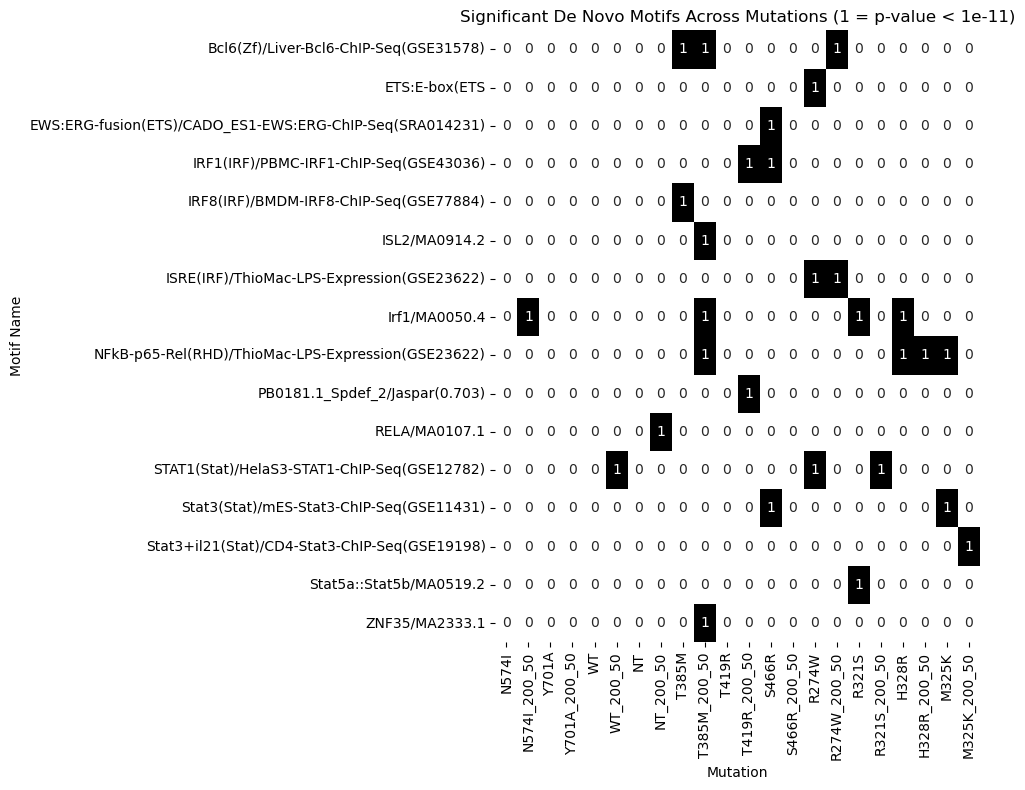

In [43]:
denovo_sig_filtered_bool = denovo_sig_filtered.copy()
denovo_sig_filtered_bool[df_pivot.columns] = np.where(denovo_sig_filtered[df_pivot.columns] <= 1e-11, 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant De Novo Motifs Across Mutations (1 = p-value < 1e-11)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

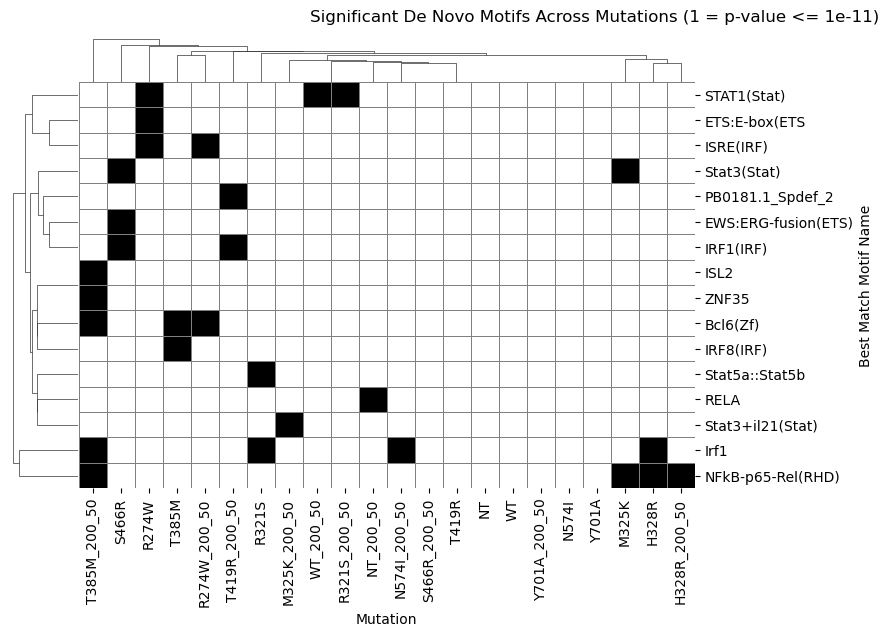

In [44]:
g = sns.clustermap(
    denovo_sig_filtered_bool,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    lw=0.5,
    linecolor="gray",
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(12, 6)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (1 = p-value <= 1e-11)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Best Match Motif Name')

plt.show()

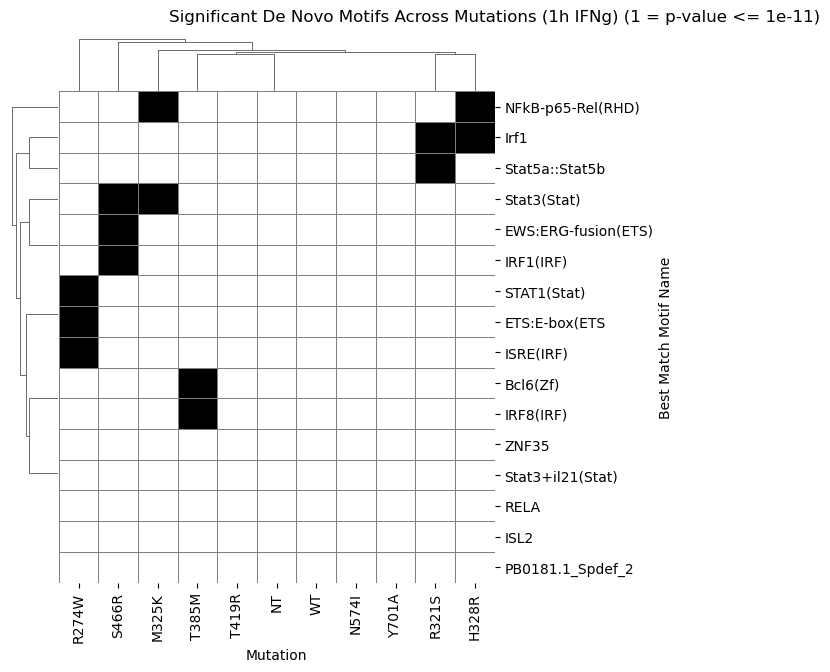

In [45]:
# Filter columns to exclude mutations ending in '_200_50'
filtered_columns = [col for col in denovo_sig_filtered_bool.columns if not col.endswith('_200_50')]
denovo_sig_filtered_bool_subset = denovo_sig_filtered_bool[filtered_columns]

# Create the clustermap
g = sns.clustermap(
    denovo_sig_filtered_bool_subset,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    lw=0.5,
    linecolor="gray",
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 6)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (1h IFNg) (1 = p-value <= 1e-11)', y=1.02) 
g.ax_heatmap.set_xticklabels([label.get_text() for label in g.ax_heatmap.get_xticklabels()], rotation=90)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Best Match Motif Name')

plt.show()

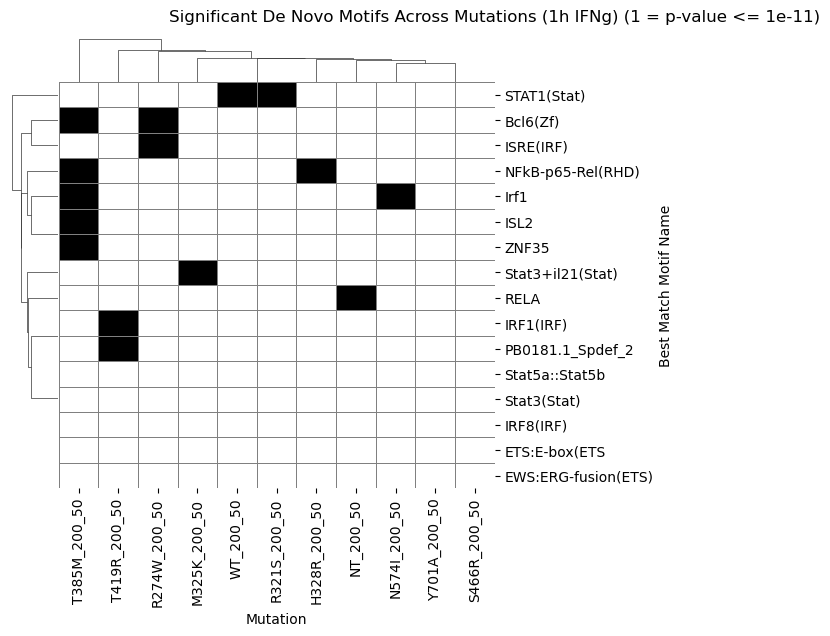

In [46]:
# Filter columns to include only mutations ending in '_200_50'
filtered_columns = [col for col in denovo_sig_filtered_bool.columns if col.endswith('_200_50')]
denovo_sig_filtered_bool_subset = denovo_sig_filtered_bool[filtered_columns]

# Create the clustermap
g = sns.clustermap(
    denovo_sig_filtered_bool_subset,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=False,
    lw=0.5,
    linecolor="gray",
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 6)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (1h IFNg) (1 = p-value <= 1e-11)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Best Match Motif Name')

plt.show()

#### Matches and scores

In [47]:
from bs4 import BeautifulSoup
import re
import glob

In [48]:
# Function to extract score and offset from text
def extract_score_offset(text):
    score = None
    offset = None
    try:
        # Match Score: followed by a number (int or float)
        score_match = re.search(r'Score:\s*([\d.]+)', text)
        if score_match:
            score_str = score_match.group(1)
            score = float(score_str)  
        # Match Offset: followed by an integer (positive or negative)
        offset_match = re.search(r'Offset:\s*([-]?\d+)', text)
        if offset_match:
            offset = int(offset_match.group(1))
    except (ValueError, TypeError) as e:
        print(f"Error parsing text: {text}, Error: {e}")
    return score, offset

# Base directory containing mutation subfolders
base_dir = 'up_IFNg'

# Initialize lists to store data
all_motif_names = []
all_scores = []
all_offsets = []
all_motif_numbers = []
all_mutations = []

# Find all subfolders matching up_* (only directories)
mutation_folders = [f for f in glob.glob(os.path.join(base_dir, 'up_*')) if os.path.isdir(f)]
if not mutation_folders:
    print(f"No mutation folders found in {base_dir}")
    exit(1)

for mut_folder in mutation_folders:
    # Extract mutation name from folder (e.g., up_WT -> WT)
    mut_name = os.path.basename(mut_folder).replace('up_', '')
    
    # Path to homerResults directory
    homer_dir = os.path.join(mut_folder, 'homerResults')
    
    # Find all motif*.info.html files in homerResults
    file_pattern = os.path.join(homer_dir, 'motif*.info.html')
    html_files = glob.glob(file_pattern)
    
    if not html_files:
        print(f"No motif files found in {homer_dir}")
        continue
    
    for file_path in html_files:
        # Extract motif number from filename (e.g., motif1.info.html -> 1)
        filename = os.path.basename(file_path)
        motif_number_match = re.search(r'motif(\d+)\.info\.html', filename)
        if motif_number_match:
            motif_number = int(motif_number_match.group(1))
        else:
            print(f"Could not extract motif number from {filename}, skipping.")
            continue
        
        # Read the HTML file
        if not os.path.exists(file_path):
            print(f"File {file_path} not found, skipping.")
            continue
        
        with open(file_path, 'r') as file:
            html_content = file.read()
        
        # Parse the HTML
        soup = BeautifulSoup(html_content, 'html.parser')
        
        # Find the first occurrence of <H3>Matches to Known Motifs</H3>
        matches_section = soup.find('h3', string='Matches to Known Motifs')
        
        if matches_section:
            # Find all <H4> tags containing motif names after the Matches section
            motif_headers = matches_section.find_all_next('h4')
            
            for header in motif_headers:
                # Extract motif name from <H4> tag
                motif_name = header.text.strip()
                
                # Find the next table containing Match Rank, Score, Offset, etc.
                table = header.find_next('table')
                if table:
                    # Try to find the cell containing Score and Offset
                    cells = table.find_all('td')
                    for cell in cells:
                        cell_text = cell.text.strip()
                        score, offset = extract_score_offset(cell_text)
                        if score is not None and offset is not None:
                            all_motif_names.append(motif_name)
                            all_scores.append(score)
                            all_offsets.append(offset)
                            all_motif_numbers.append(motif_number)
                            all_mutations.append(mut_name)
                            break  # Move to next motif after finding valid data
        else:
            print(f"No 'Matches to Known Motifs' section found in {filename}")

# Create DataFrame
df_denovo = pd.DataFrame({
    'Mutation': all_mutations,
    'Motif Number': all_motif_numbers,
    'Motif Name': all_motif_names,
    'Score': all_scores,
    'Offset': all_offsets
})

In [49]:
df_denovo[(df_denovo['Mutation'] == 'WT') & (df_denovo['Motif Number'] == 1)]

,Mutation,Motif Number,Motif Name,Score,Offset
3080,WT,1,STAT1(Stat)/HelaS3-STAT1-ChIP-Seq(GSE12782)/Homer,0.92,-2
3081,WT,1,STAT4(Stat)/CD4-Stat4-ChIP-Seq(GSE22104)/Homer,0.90,-1
3082,WT,1,Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0.89,-1
3083,WT,1,Stat3+il21(Stat)/CD4-Stat3-ChIP-Seq(GSE19198)/...,0.89,-2
3084,WT,1,Stat3(Stat)/mES-Stat3-ChIP-Seq(GSE11431)/Homer,0.87,-1
3085,WT,1,Stat4/MA0518.2/Jaspar,0.87,0
3086,WT,1,STAT1/MA0137.4/Jaspar,0.86,0
3087,WT,1,STAT3/MA0144.3/Jaspar,0.83,0
3088,WT,1,Stat5a::Stat5b/MA0519.2/Jaspar,0.82,0
3089,WT,1,Stat5a/MA1624.2/Jaspar,0.81,0


In [50]:
df_denovo.sort_values('Score', ascending=False)

,Mutation,Motif Number,Motif Name,Score,Offset
820,R274W,4,NFkB-p65-Rel(RHD)/ThioMac-LPS-Expression(GSE23...,0.99,0
3420,H328R,2,NFkB-p65-Rel(RHD)/ThioMac-LPS-Expression(GSE23...,0.99,0
3560,H328R_200_50,1,NFkB-p65-Rel(RHD)/ThioMac-LPS-Expression(GSE23...,0.99,0
300,R321S,3,NFkB-p65-Rel(RHD)/ThioMac-LPS-Expression(GSE23...,0.99,0
680,N574I_200_50,1,Irf1/MA0050.4/Jaspar,0.98,0
...,...,...,...,...,...
2306,Y701A_200_50,3,PBX1/MA0070.2/Jaspar,0.52,-3
18,T419R_200_50,4,ZNF574/MA1982.2/Jaspar,0.51,-5
19,T419R_200_50,4,ZNF415(Zf)/HEK293-ZNF415.GFP-ChIP-Seq(GSE58341...,0.51,-1
2308,Y701A_200_50,3,PH0026.1_Duxbl/Jaspar,0.51,-6


Non-finite values detected in pivot_df. Filling NaN with 0.


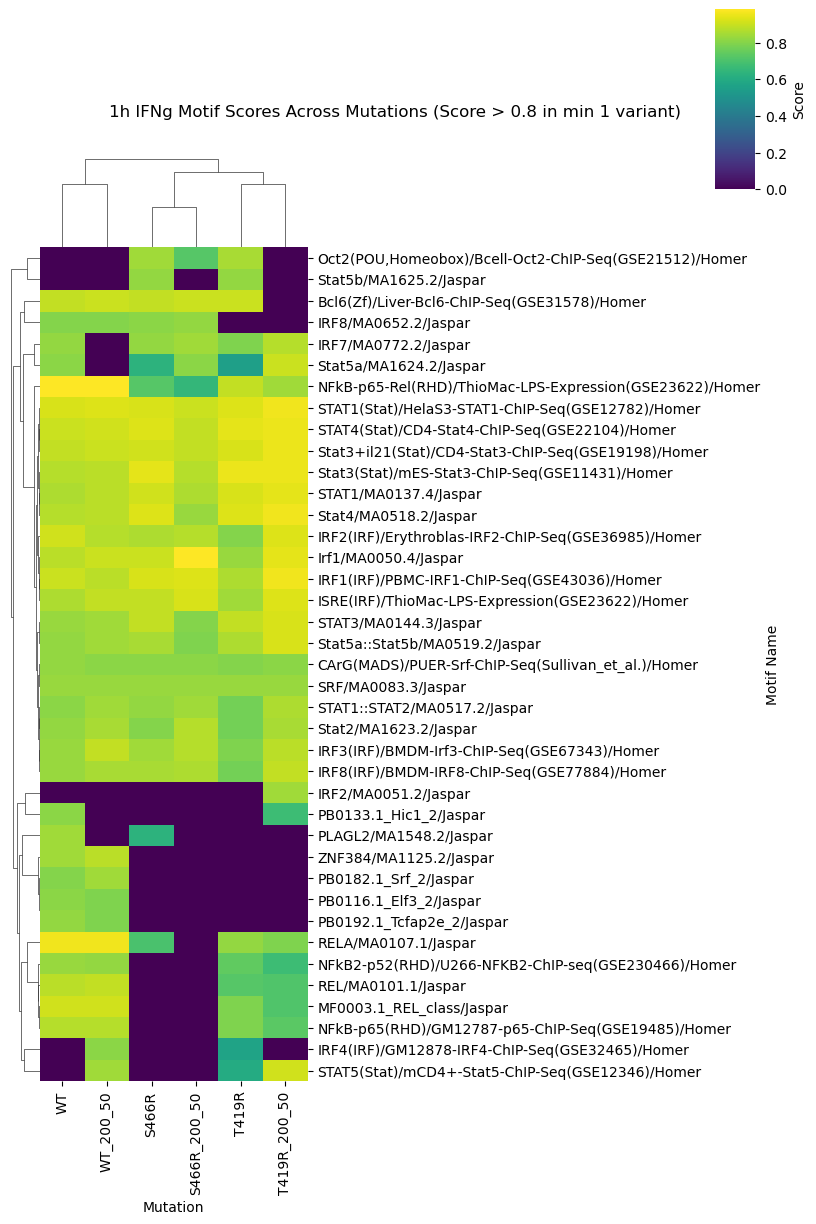

In [76]:
pivot_df = df_denovo[df_denovo['Mutation'].isin(['WT', 'WT_200_50', 'T419R','T419R_200_50', 'S466R', 'S466R_200_50'])]

pivot_df = pivot_df.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.8]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    dendrogram_ratio=0.1,  # Size of dendrograms
    figsize=(8, max(10, len(pivot_df) * 0.2)),  # Scale height with number of motifs
    cbar_pos=(0.9, 0.95, 0.05, 0.18)  # Position of colorbar
)

g.fig.suptitle('1h IFNg Motif Scores Across Mutations (Score > 0.8 in min 1 variant)', 
               x=0.5, y=1.02, ha='center', va='bottom')  # Center the title
g.ax_heatmap.set_ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()


Non-finite values detected in pivot_df. Filling NaN with 0.


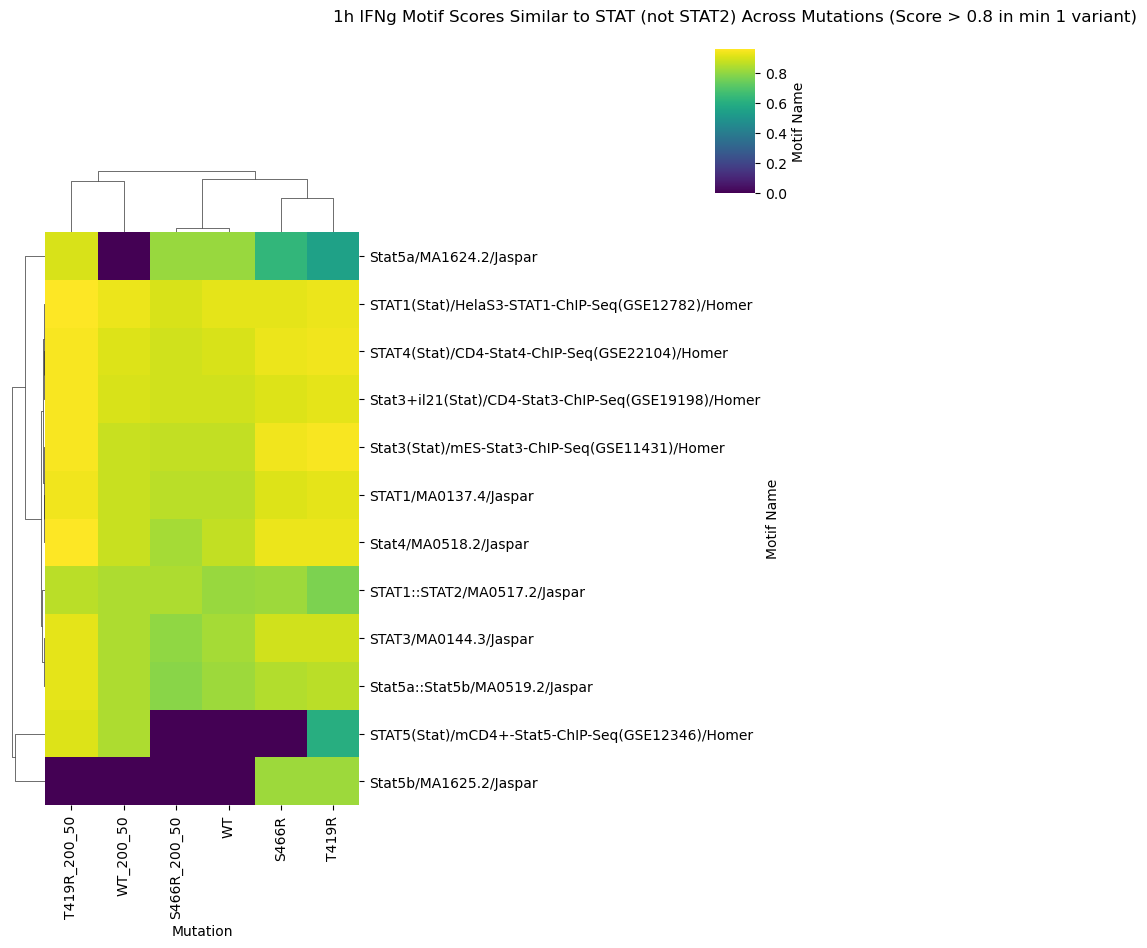

In [70]:
pivot_df = df_denovo[df_denovo['Mutation'].isin(['WT', 'WT_200_50', 'T419R','T419R_200_50', 'S466R', 'S466R_200_50'])]
pivot_df = pivot_df[pivot_df['Motif Name'].str.contains(r'STAT(?!2)', case=False, na=False, regex=True)]

pivot_df = pivot_df.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.8]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    dendrogram_ratio=0.1,  # Size of dendrograms
    figsize=(8, max(8, len(pivot_df) * 0.2)),  # Scale height with number of motifs
    cbar_pos=(0.9, 0.95, 0.05, 0.18)  # Position of colorbar
)

# Customize plot
plt.title('1h IFNg Motif Scores Similar to STAT (not STAT2) Across Mutations (Score > 0.8 in min 1 variant)', pad=20)
plt.ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()


Non-finite values detected in pivot_df. Filling NaN with 0.


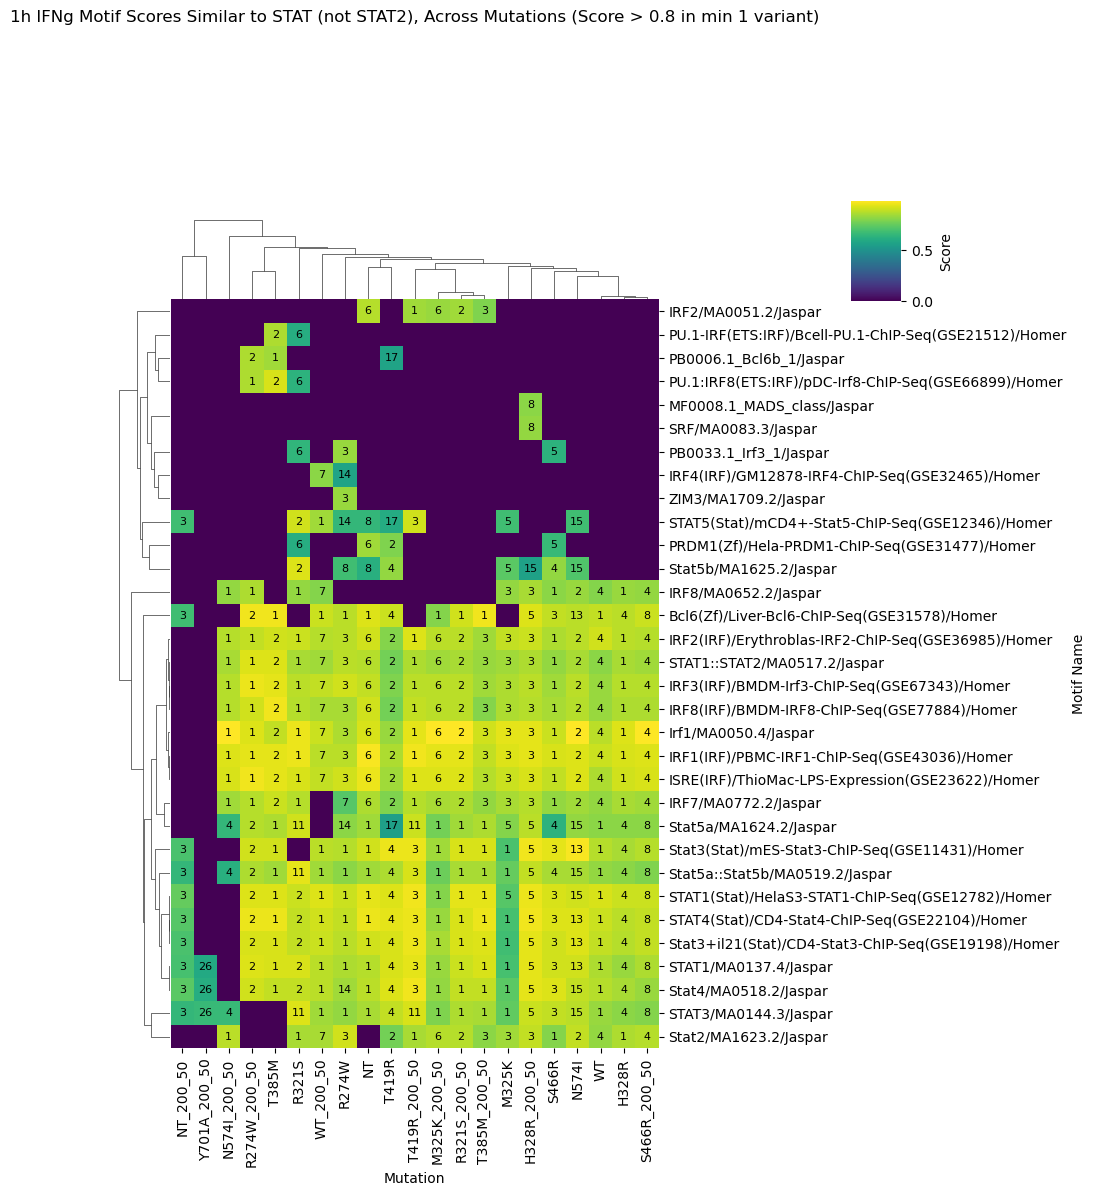

In [66]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains(r'STAT(?!2)', case=False, na=False, regex=True)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

all_mutations = df_denovo['Mutation'].unique()

# Create pivot table for scores
pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

# Create pivot table for motif numbers (for annotations)
pivot_motif_numbers = df_filtered.pivot_table(
    values='Motif Number',
    index='Motif Name',
    columns='Mutation',
    aggfunc='first'  # Take the first Motif Number for duplicates
)

# Filter rows where max score across mutations is > 0.8
pivot_df = pivot_df[pivot_df.max(axis=1) > 0.8]

# Align pivot_motif_numbers with pivot_df to ensure same index and columns
pivot_motif_numbers = pivot_motif_numbers.loc[pivot_df.index, pivot_df.columns]

# Check for non-finite values (NaN or inf) in pivot_df
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g = sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(10, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Get the reordered indices from the clustermap
row_order = g.dendrogram_row.reordered_ind
col_order = g.dendrogram_col.reordered_ind

# Reorder pivot_df and pivot_motif_numbers to match clustermap order
pivot_df_reordered = pivot_df.iloc[row_order, col_order]
pivot_motif_numbers_reordered = pivot_motif_numbers.iloc[row_order, col_order]

# Add annotations for Motif Number
for i in range(pivot_df_reordered.shape[0]):
    for j in range(pivot_df_reordered.shape[1]):
        motif_num = pivot_motif_numbers_reordered.iloc[i, j]
        if pd.notna(motif_num):  # Only annotate if motif number exists
            g.ax_heatmap.text(
                j + 0.5,  # Center in x
                i + 0.5,  # Center in y
                f'{int(motif_num)}',  # Convert to int to avoid decimal
                ha='center',
                va='center',
                color='white' if pivot_df_reordered.iloc[i, j] < 0.5 else 'black',  # Contrast based on score
                fontsize=8
            )

# Customize plot
g.ax_heatmap.set_title('1h IFNg Motif Scores Similar to STAT (not STAT2), Across Mutations (Score > 0.8 in min 1 variant)', pad=200)
g.ax_heatmap.set_ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

Filter by motifs close to STAT, that is, de novo motifs that include a STAT in their list of matches.

In [53]:
df_denovo.shape

(3840, 5)

In [54]:
df_denovo[df_denovo['Motif Name'].str.contains('STAT|stat', case=False, na=False)]

,Mutation,Motif Number,Motif Name,Score,Offset
33,T419R_200_50,11,STAT3/MA0144.3/Jaspar,0.66,-1
34,T419R_200_50,11,Stat5a/MA1624.2/Jaspar,0.65,-1
57,T419R_200_50,1,STAT1::STAT2/MA0517.2/Jaspar,0.86,0
58,T419R_200_50,1,Stat2/MA1623.2/Jaspar,0.85,2
110,T419R_200_50,3,STAT1(Stat)/HelaS3-STAT1-ChIP-Seq(GSE12782)/Homer,0.96,-2
...,...,...,...,...,...
3795,T385M_200_50,3,STAT1::STAT2/MA0517.2/Jaspar,0.83,-1
3797,T385M_200_50,3,Stat2/MA1623.2/Jaspar,0.81,0
3823,T385M_200_50,6,STAT3/MA0144.3/Jaspar,0.67,-1
3824,T385M_200_50,6,Stat5a/MA1624.2/Jaspar,0.67,-1


In [55]:
df_denovo[df_denovo['Motif Name'].str.contains('STAT', case=False, na=False)]['Motif Number'].unique()

array([11,  1,  3, 20,  2,  6,  5,  4, 14, 21,  8,  7, 17, 26, 15, 13, 16])

In [56]:
df_denovo[df_denovo['Motif Name'].str.contains('STAT', case=False, na=False)][['Motif Number', 'Mutation']].drop_duplicates().values

array([[11, 'T419R_200_50'],
       [1, 'T419R_200_50'],
       [3, 'T419R_200_50'],
       [20, 'R321S'],
       [11, 'R321S'],
       [1, 'R321S'],
       [2, 'R321S'],
       [6, 'R321S'],
       [1, 'M325K'],
       [3, 'M325K'],
       [5, 'M325K'],
       [6, 'M325K'],
       [1, 'R321S_200_50'],
       [2, 'R321S_200_50'],
       [3, 'R321S_200_50'],
       [4, 'N574I_200_50'],
       [1, 'N574I_200_50'],
       [14, 'R274W'],
       [21, 'R274W'],
       [1, 'R274W'],
       [8, 'R274W'],
       [3, 'R274W'],
       [7, 'R274W'],
       [4, 'S466R'],
       [1, 'S466R'],
       [3, 'S466R'],
       [5, 'S466R'],
       [1, 'T385M'],
       [2, 'T385M'],
       [4, 'T419R'],
       [2, 'T419R'],
       [6, 'T419R'],
       [17, 'T419R'],
       [1, 'NT'],
       [8, 'NT'],
       [6, 'NT'],
       [26, 'Y701A_200_50'],
       [1, 'M325K_200_50'],
       [2, 'M325K_200_50'],
       [6, 'M325K_200_50'],
       [15, 'N574I'],
       [2, 'N574I'],
       [13, 'N574I'],
       [7, 'N

Non-finite values detected in pivot_df. Filling NaN with 0.


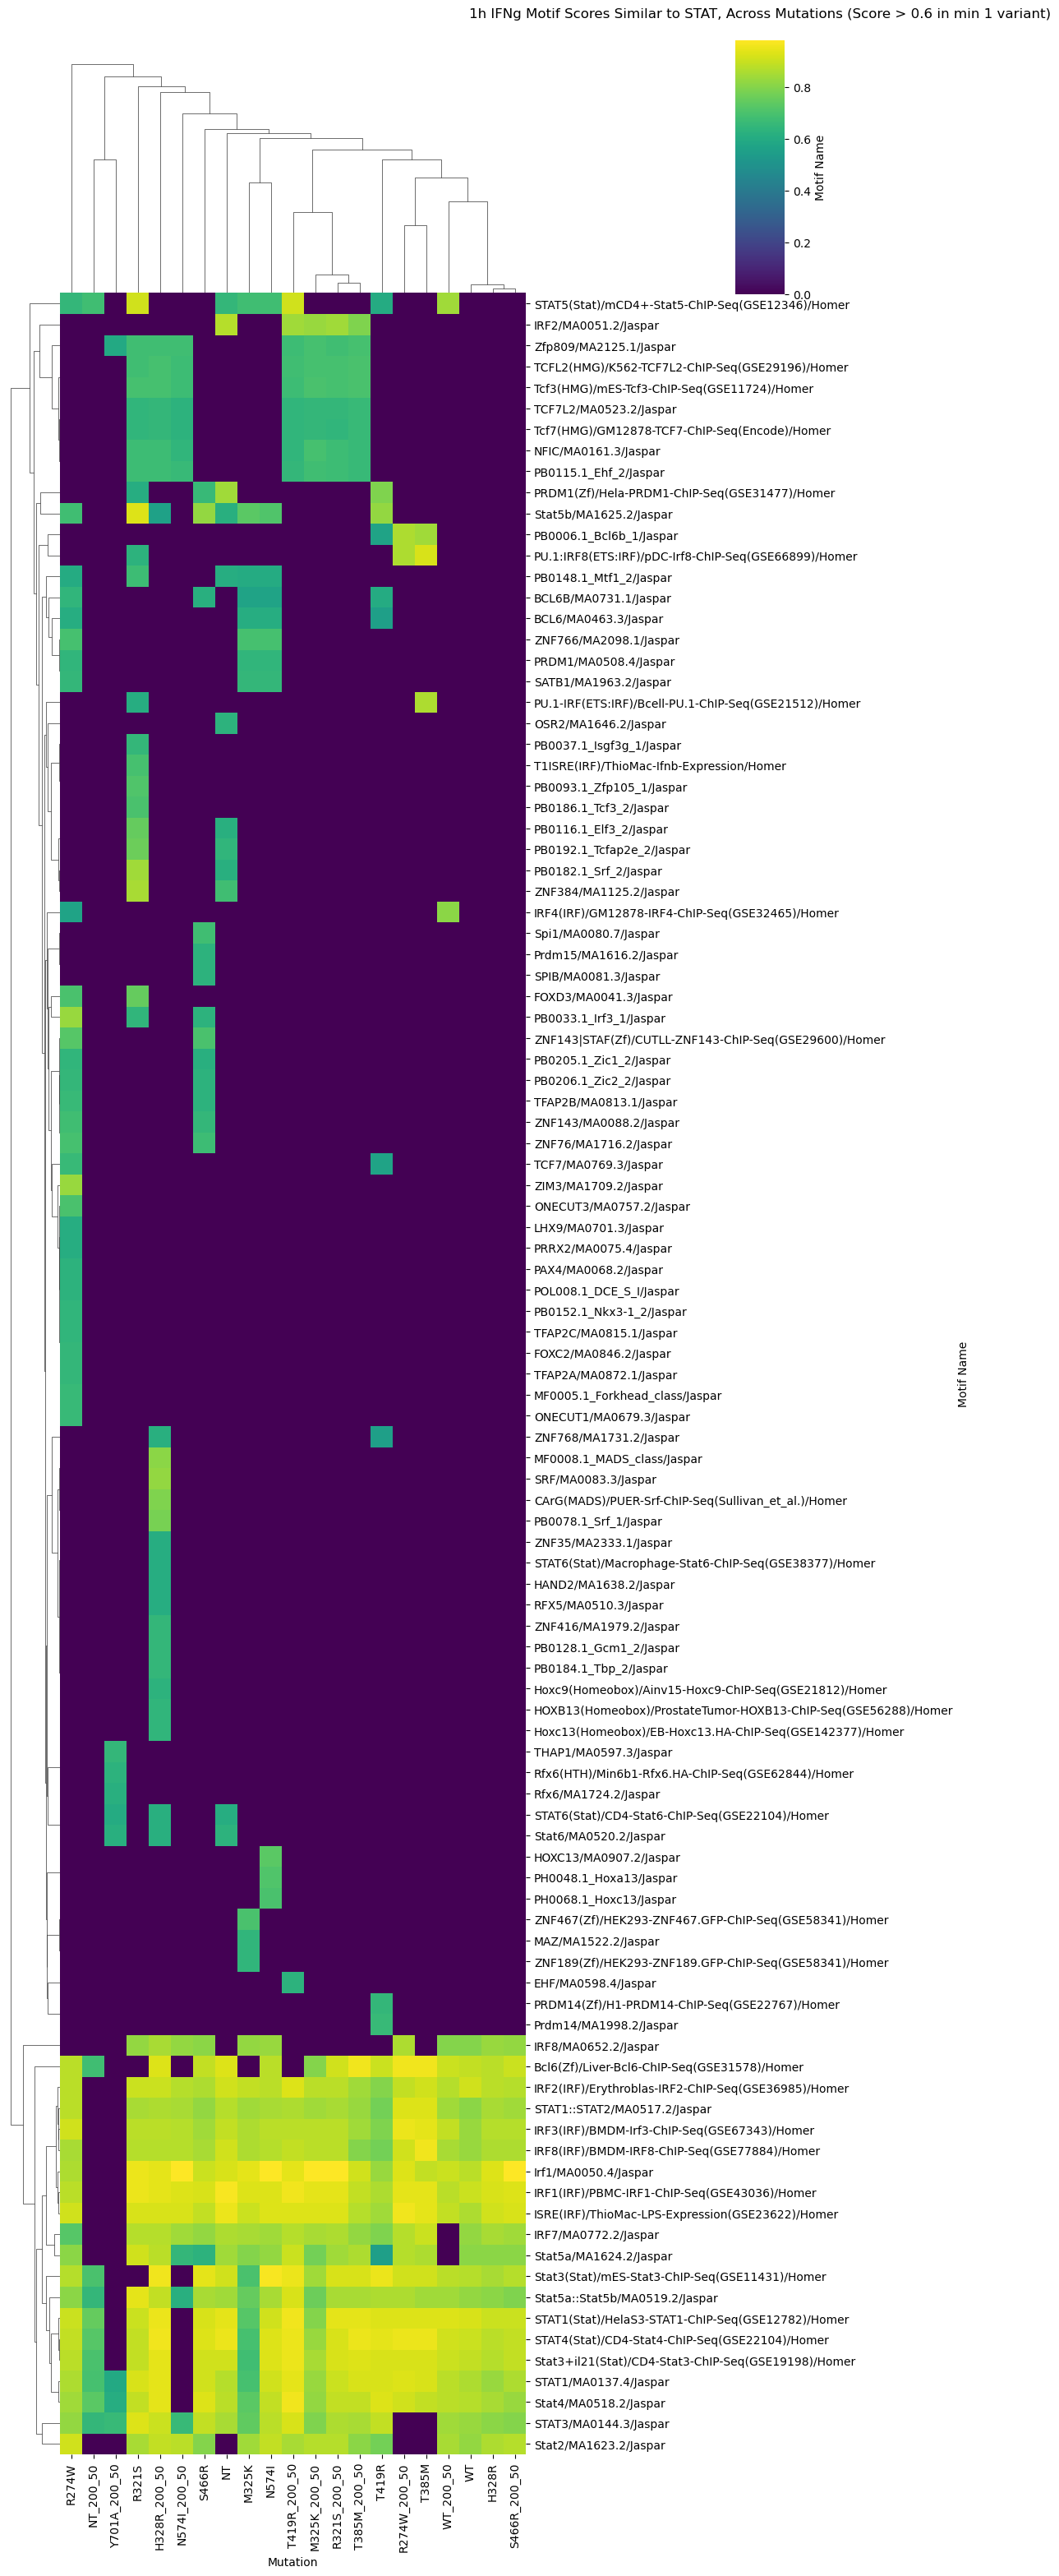

In [57]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains('STAT', case=False, na=False)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

pivot_df = pivot_df[pivot_df.max(axis=1) > 0.6]

# Check for non-finite values (NaN or inf)
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g= sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(12, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Customize plot
plt.title('1h IFNg Motif Scores Similar to STAT, Across Mutations (Score > 0.6 in min 1 variant)', pad=20)
plt.ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

In [58]:
# Group by Mutation and Motif Name to get counts
counts = df_denovo.groupby(['Mutation', 'Motif Name']).size().reset_index(name='Count')

# Filter for Mutation and Motif Name pairs with Count > 1
valid_pairs = counts[counts['Count'] > 1][['Mutation', 'Motif Name']]

# Filter original df_denovo to keep only rows matching valid pairs
df_filtered = df_denovo.merge(valid_pairs, on=['Mutation', 'Motif Name'], how='inner')

# Print the filtered DataFrame with all original columns
df_filtered.head(20)
df_filtered.to_csv("denovo_motifs_repeat.csv", index=False)

Non-finite values detected in pivot_df. Filling NaN with 0.


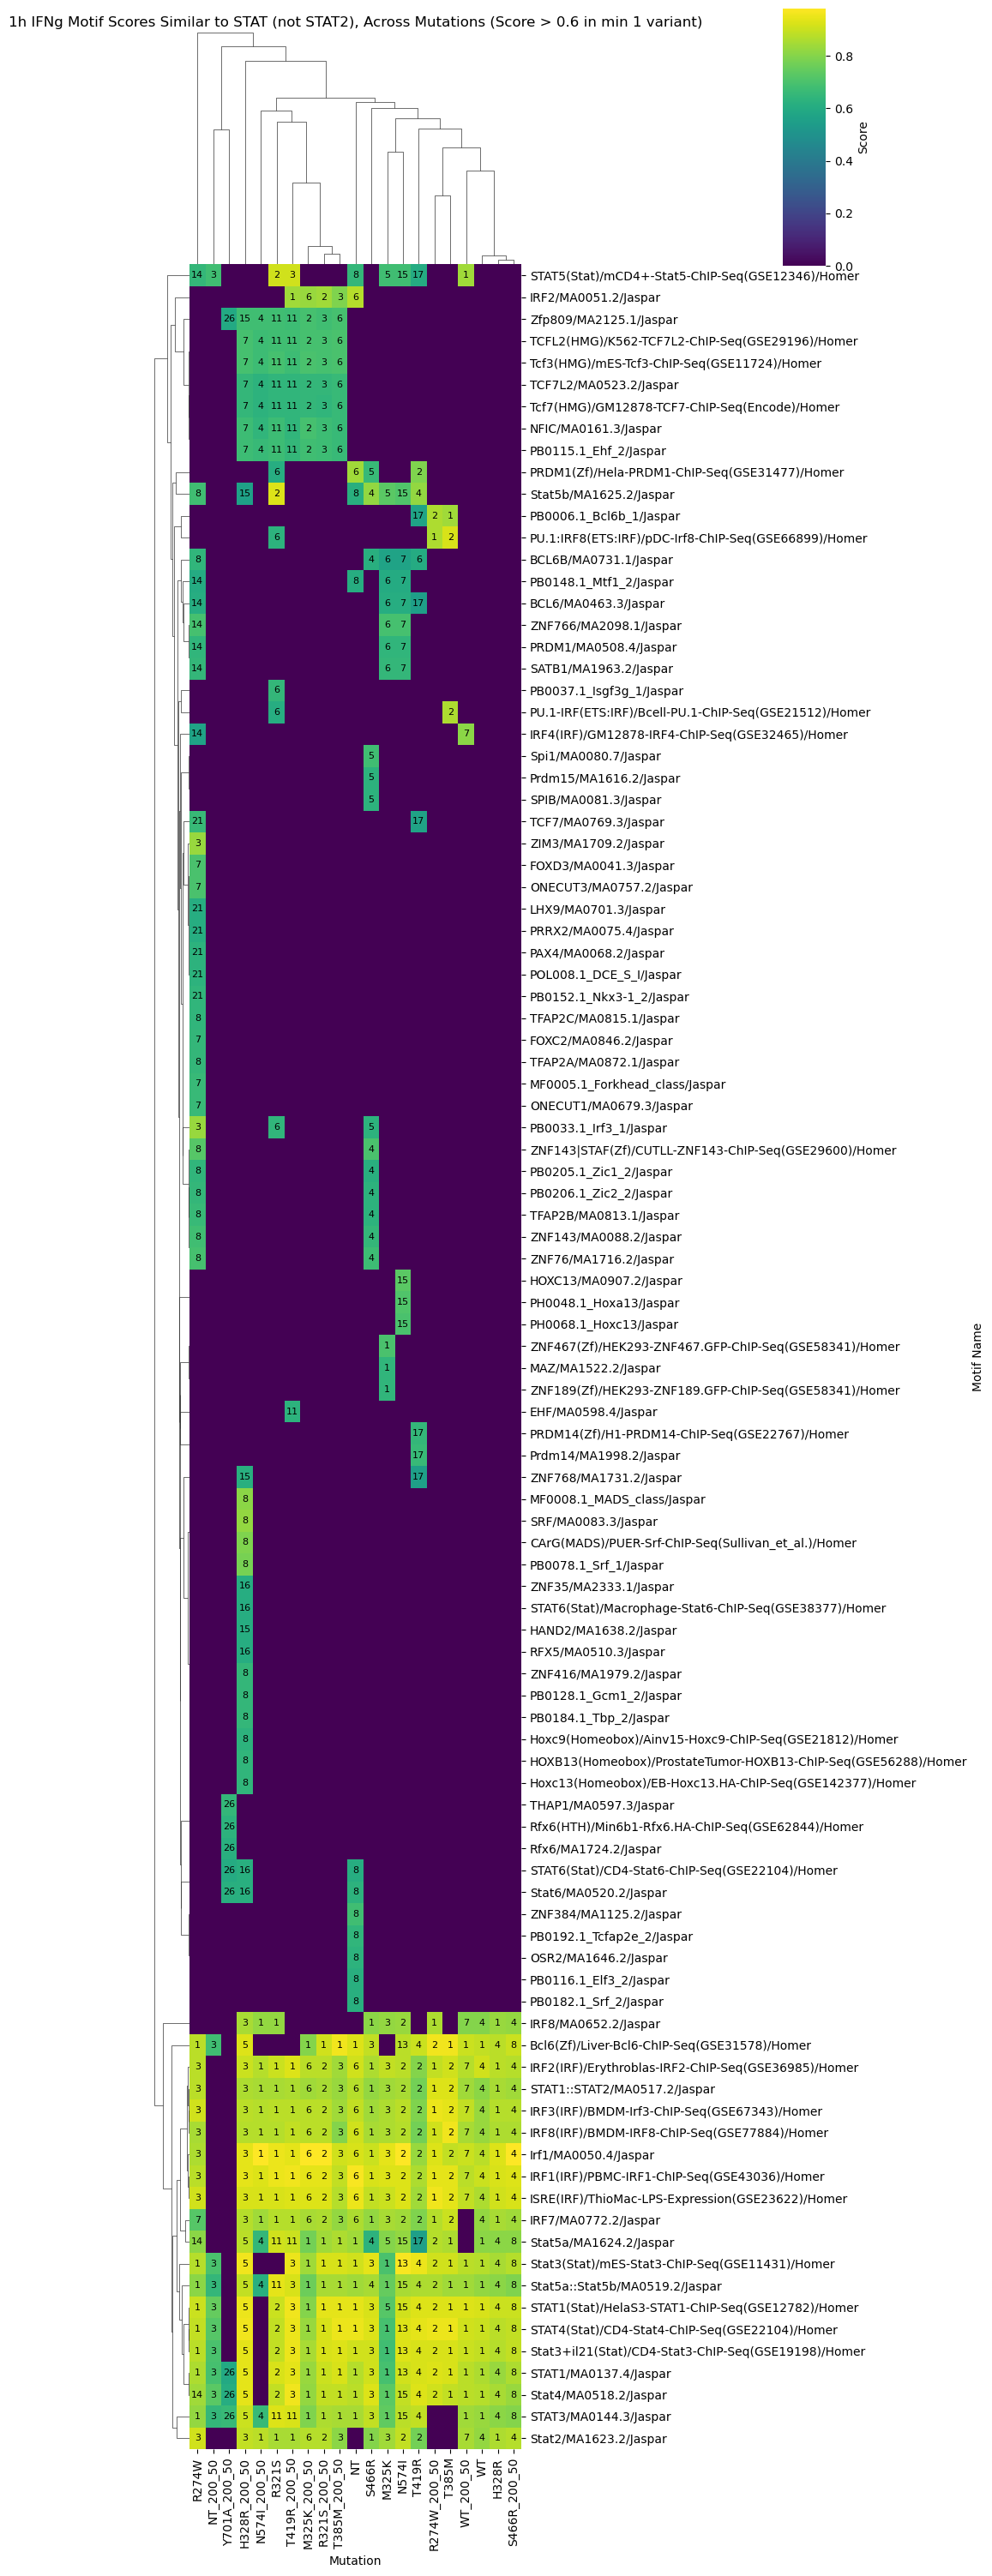

In [59]:
# Get unique Motif Number and Mutation combinations for STAT motifs
unique_combinations = df_denovo[df_denovo['Motif Name'].str.contains(r'STAT(?!2)', case=False, na=False, regex=True)][['Motif Number', 'Mutation']].drop_duplicates()

# Filter df_denovo to include only rows matching unique_combinations
df_filtered = df_denovo[df_denovo.set_index(['Motif Number', 'Mutation']).index.isin(unique_combinations.set_index(['Motif Number', 'Mutation']).index)]

all_mutations = df_denovo['Mutation'].unique()

# Create pivot table for scores
pivot_df = df_filtered.pivot_table(
    values='Score',
    index='Motif Name',
    columns='Mutation',
    aggfunc='max'  # Use max score for duplicates
)

# Create pivot table for motif numbers (for annotations)
pivot_motif_numbers = df_filtered.pivot_table(
    values='Motif Number',
    index='Motif Name',
    columns='Mutation',
    aggfunc='first'  # Take the first Motif Number for duplicates
)

# Filter rows where max score across mutations is > 0.6
pivot_df = pivot_df[pivot_df.max(axis=1) > 0.6]

# Align pivot_motif_numbers with pivot_df to ensure same index and columns
pivot_motif_numbers = pivot_motif_numbers.loc[pivot_df.index, pivot_df.columns]

# Check for non-finite values (NaN or inf) in pivot_df
if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
    print("Non-finite values detected in pivot_df. Filling NaN with 0.")
    pivot_df = pivot_df.fillna(0)  # Replace NaN with 0
    # Check for infinite values
    if not pivot_df.apply(lambda x: np.isfinite(x)).all().all():
        print("Infinite values detected in pivot_df. Problematic rows:")
        print(pivot_df[~pivot_df.apply(lambda x: np.isfinite(x)).all(axis=1)])
        exit(1)

# Generate clustermap with hierarchical clustering
g = sns.clustermap(
    pivot_df,
    cmap='viridis',  # Color map for scores
    cbar_kws={'label': 'Score'},  # Colorbar label
    figsize=(10, max(10, len(pivot_df) * 0.3)),  # Scale height with number of motifs
    dendrogram_ratio=0.1,  # Size of dendrograms
    cbar_pos=(0.75, 0.90, 0.05, 0.1)  # Position of colorbar
)

# Get the reordered indices from the clustermap
row_order = g.dendrogram_row.reordered_ind
col_order = g.dendrogram_col.reordered_ind

# Reorder pivot_df and pivot_motif_numbers to match clustermap order
pivot_df_reordered = pivot_df.iloc[row_order, col_order]
pivot_motif_numbers_reordered = pivot_motif_numbers.iloc[row_order, col_order]

# Add annotations for Motif Number
for i in range(pivot_df_reordered.shape[0]):
    for j in range(pivot_df_reordered.shape[1]):
        motif_num = pivot_motif_numbers_reordered.iloc[i, j]
        if pd.notna(motif_num):  # Only annotate if motif number exists
            g.ax_heatmap.text(
                j + 0.5,  # Center in x
                i + 0.5,  # Center in y
                f'{int(motif_num)}',  # Convert to int to avoid decimal
                ha='center',
                va='center',
                color='white' if pivot_df_reordered.iloc[i, j] < 0.5 else 'black',  # Contrast based on score
                fontsize=8
            )

# Customize plot
g.ax_heatmap.set_title('1h IFNg Motif Scores Similar to STAT (not STAT2), Across Mutations (Score > 0.6 in min 1 variant)', pad=200)
g.ax_heatmap.set_ylabel('Motif Name')
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha='center')

plt.show()

## Comparison - WT vs T419R (known motifs)

### Default promoter region (-300, +50)

Before merging the databases, check for duplicate motifs.

In [123]:
# Load known motif results
WT_motifs = pd.read_csv("up_IFNg/up_WT/knownResults.txt", sep="\t")
T419R_motifs = pd.read_csv("up_IFNg/up_T419R/knownResults.txt", sep="\t")

In [124]:
print(WT_motifs[WT_motifs["Motif Name"].duplicated()]["Motif Name"])
print(T419R_motifs[T419R_motifs["Motif Name"].duplicated()]["Motif Name"])

471    RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer
Name: Motif Name, dtype: object
359    RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer
Name: Motif Name, dtype: object


In [125]:
WT_motifs[WT_motifs["Motif Name"] == "RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer"]

,Motif Name,Consensus,P-value,Log P-value,q-value (Benjamini),# of Target Sequences with Motif(of 95),% of Target Sequences with Motif,# of Background Sequences with Motif(of 46038),% of Background Sequences with Motif
470,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,0.0,1.0,0.0,0.00%,504.6,1.10%
471,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,0.0,1.0,0.0,0.00%,504.6,1.10%


In [126]:
T419R_motifs[T419R_motifs["Motif Name"] == "RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer"]

,Motif Name,Consensus,P-value,Log P-value,q-value (Benjamini),# of Target Sequences with Motif(of 147),% of Target Sequences with Motif,# of Background Sequences with Motif(of 45083),% of Background Sequences with Motif
358,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,-0.2541,1.0,1.0,0.68%,456.3,1.01%
359,RORgt(NR)/EL4-RORgt.Flag-ChIP-Seq(GSE56019)/Homer,AAYTAGGTCA,1.0,-0.2541,1.0,1.0,0.68%,456.3,1.01%


Merge dataframes.

In [127]:
comparison = pd.merge(WT_motifs.drop_duplicates(subset="Motif Name"), T419R_motifs.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_WT", "_T419R"))

In [128]:
WT_motifs.drop_duplicates(subset="Motif Name").shape

(471, 9)

In [129]:
T419R_motifs.drop_duplicates(subset="Motif Name").shape

(471, 9)

In [130]:
comparison.shape

(471, 17)

**Motifs intersection**

Check for motifs not present in both dataframes.

In [131]:
comparison.isna().sum()

Motif Name                                        0
Consensus_WT                                      0
P-value_WT                                        0
Log P-value_WT                                    0
q-value (Benjamini)_WT                            0
# of Target Sequences with Motif(of 95)           0
% of Target Sequences with Motif_WT               0
# of Background Sequences with Motif(of 46038)    0
% of Background Sequences with Motif_WT           0
Consensus_T419R                                   0
P-value_T419R                                     0
Log P-value_T419R                                 0
q-value (Benjamini)_T419R                         0
# of Target Sequences with Motif(of 147)          0
% of Target Sequences with Motif_T419R            0
# of Background Sequences with Motif(of 45083)    0
% of Background Sequences with Motif_T419R        0
dtype: int64

In [132]:
comparison[(comparison["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] != "0.00%")].shape

(13, 17)

In [133]:
comparison[(comparison["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] == "0.00%")].shape

(1, 17)

In [134]:
comparison[(comparison["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] != "0.00%")][["% of Target Sequences with Motif_T419R", "P-value_T419R"]].sort_values("P-value_T419R", ascending=True).head(10)

,% of Target Sequences with Motif_T419R,P-value_T419R
156,2.04%,1.0
187,2.04%,1.0
237,1.36%,1.0
278,1.36%,1.0
312,0.68%,1.0
315,0.68%,1.0
319,0.68%,1.0
321,0.68%,1.0
346,0.68%,1.0
370,0.68%,1.0


In [135]:
comparison[(comparison["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison["% of Target Sequences with Motif_T419R"] == "0.00%")][["% of Target Sequences with Motif_WT", "P-value_WT"]].sort_values("P-value_WT", ascending=True).head(10)

,% of Target Sequences with Motif_WT,P-value_WT
127,1.05%,1.0


The same list of motifs was found for both WT and T419R upregulated genes. Some motifs are found with very low frequency (<0.01 \%) in one of the gene lists, but these motifs are not significant in the other gene list.

**P-value distributions**

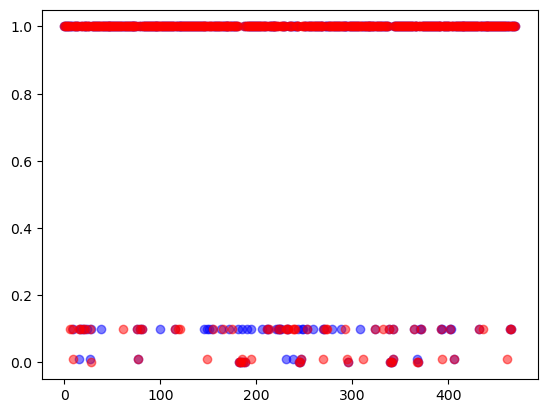

In [136]:
plt.scatter(comparison.index, comparison["P-value_WT"], color="blue", label="WT", alpha=0.5)
plt.scatter(comparison.index, comparison["P-value_T419R"], color="red", label="T419R", alpha=0.5)

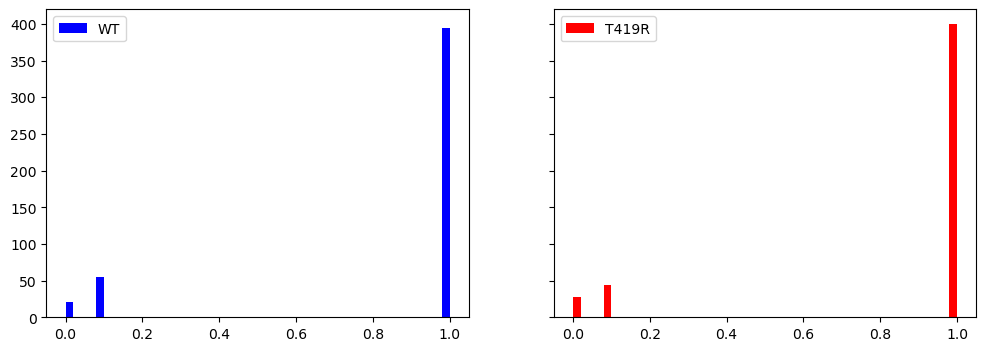

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1, ax2 = axes.flatten()

ax1.hist(comparison["P-value_WT"], bins=50, color="blue", label="WT")
ax2.hist(comparison["P-value_T419R"], bins=50, color="red", label="T419R")

ax1.legend()
ax2.legend()

plt.show()

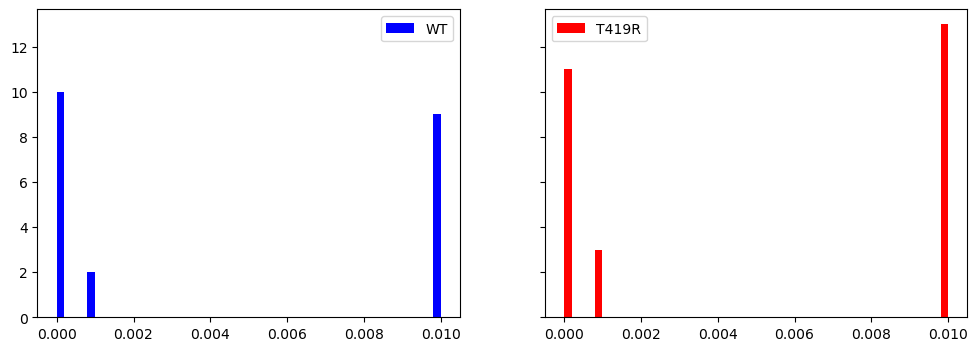

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax1, ax2 = axes.flatten()

ax1.hist(comparison[comparison["P-value_WT"] <0.05]["P-value_WT"], bins=50, color="blue", label="WT")
ax2.hist(comparison[comparison["P-value_T419R"] <0.05]["P-value_T419R"], bins=50, color="red", label="T419R")

ax1.legend()
ax2.legend()

plt.show()

The number of significant motifs is slightly higher for T419R than for WT.

**Comparison**

Motifs significant for T419R and not significant for WT.

In [139]:
comparison_uniqueT419R = comparison[(comparison["P-value_T419R"] < 0.05) & (comparison["P-value_WT"] > 0.05)]

In [140]:
comparison_uniqueT419R.shape

(10, 17)

In [174]:
comparison_uniqueT419R[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]].sort_values(by="P-value_T419R", ascending=True)

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
28,Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0.1,0.001,27.37%,29.93%,NNNCTTTCCAGGAAA,0.3757,0.0090
9,Ascl2(bHLH)/ESC-Ascl2-ChIP-Seq(GSE97712)/Homer,0.1,0.010,23.16%,24.49%,SSRGCAGCTGCH,0.6067,0.1669
149,HEB(bHLH)/mES-Heb-ChIP-Seq(GSE53233)/Homer,0.1,0.010,34.74%,36.05%,VCAGCTGBNN,0.5956,0.1398
185,IRF4(IRF)/GM12878-IRF4-ChIP-Seq(GSE32465)/Homer,0.1,0.010,10.53%,11.56%,ACTGAAACCA,0.4469,0.0790
195,KLF14(Zf)/HEK293-KLF14.GFP-ChIP-Seq(GSE58341)/...,0.1,0.010,62.11%,63.27%,RGKGGGCGKGGC,0.5460,0.1452
270,"Oct11(POU,Homeobox)/NCIH1048-POU2F3-ChIP-seq(G...",0.1,0.010,7.37%,8.16%,GATTTGCATA,0.5460,0.1600
295,PU.1-IRF(ETS:IRF)/Bcell-PU.1-ChIP-Seq(GSE21512...,1.0,0.010,27.37%,31.29%,MGGAAGTGAAAC,0.6331,0.1164
311,Ptf1a(bHLH)/Panc1-Ptf1a-ChIP-Seq(GSE47459)/Homer,1.0,0.010,40.00%,44.22%,ACAGCTGTTN,0.7493,0.1398
394,Tcf21(bHLH)/ArterySmoothMuscle-Tcf21-ChIP-Seq(...,0.1,0.010,22.11%,22.45%,NAACAGCTGG,0.4469,0.1156
461,"bZIP:IRF(bZIP,IRF)/Th17-BatF-ChIP-Seq(GSE39756...",1.0,0.010,6.32%,10.20%,NAGTTTCABTHTGACTNW,0.9101,0.1373


Motifs significant WT and not significant for T419R.

In [142]:
comparison_uniqueWT = comparison[(comparison["P-value_T419R"] > 0.05) & (comparison["P-value_WT"] < 0.05)]

In [143]:
comparison_uniqueWT.shape

(4, 17)

In [144]:
comparison_uniqueWT[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]]

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
15,Atoh1(bHLH)/Cerebellum-Atoh1-ChIP-Seq(GSE22111...,0.01,0.1,25.26%,21.09%,VNRVCAGCTGGY,0.1584,0.2034
27,Bcl11a(Zf)/HSPC-BCL11A-ChIP-Seq(GSE104676)/Homer,0.01,0.1,15.79%,12.93%,TYTGACCASWRG,0.2025,0.2287
231,Myf5(bHLH)/GM-Myf5-ChIP-Seq(GSE24852)/Homer,0.01,0.1,17.89%,14.97%,BAACAGCTGT,0.2025,0.2287
238,NFAT(RHD)/Jurkat-NFATC1-ChIP-Seq(Jolma_et_al.)...,0.01,0.1,20.00%,15.65%,ATTTTCCATT,0.1551,0.3980


### Custom promoter region (-200, +50)

The original paper (Giovannozzi S, Demeulemeester J, Schrijvers R and Gijsbers R (2021) Transcriptional Profiling of STAT1 Gain-of-Function Reveals Common and Mutation-Specific Fingerprints. Front. Immunol. 12:632997. doi: 10.3389/fimmu.2021.632997) used a region of -200,+50 around the TSS for promoter analysis.

> "We therefore identified and analyzed the promoters of the genes up-regulated after IFNγ stimulation. A short promoter region [from −200 to +50 bp around the Transcription Start Site (TSS)] was retrieved for all up-regulated genes using the Eukaryotic Promoter Database (EPD) web tool."

The next section repeats the previous analysis with those promoter region parameters, which are more restrictive than the HOMER defaults.

In [145]:
WT_motifs_200_50 = pd.read_csv("up_IFNg/up_WT_200_50/knownResults.txt", sep="\t")
T419R_motifs_200_50 = pd.read_csv("up_IFNg/up_T419R_200_50/knownResults.txt", sep="\t")

comparison_200_50 = pd.merge(WT_motifs_200_50.drop_duplicates(subset="Motif Name"), T419R_motifs_200_50.drop_duplicates(subset="Motif Name"), on="Motif Name", how="outer", suffixes=("_WT", "_T419R"))

Check for motifs present in only one of the dataframes.

In [146]:
comparison_200_50.isna().sum()

Motif Name                                        0
Consensus_WT                                      0
P-value_WT                                        0
Log P-value_WT                                    0
q-value (Benjamini)_WT                            0
# of Target Sequences with Motif(of 95)           0
% of Target Sequences with Motif_WT               0
# of Background Sequences with Motif(of 45704)    0
% of Background Sequences with Motif_WT           0
Consensus_T419R                                   0
P-value_T419R                                     0
Log P-value_T419R                                 0
q-value (Benjamini)_T419R                         0
# of Target Sequences with Motif(of 147)          0
% of Target Sequences with Motif_T419R            0
# of Background Sequences with Motif(of 45509)    0
% of Background Sequences with Motif_T419R        0
dtype: int64

In [147]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] != "0.00%")].shape

(14, 17)

In [148]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] == "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] != "0.00%")][["% of Target Sequences with Motif_T419R", "P-value_T419R"]].sort_values("P-value_T419R", ascending=True).head()

,% of Target Sequences with Motif_T419R,P-value_T419R
62,0.68%,1.0
156,1.36%,1.0
187,0.68%,1.0
278,1.36%,1.0
312,0.68%,1.0


In [149]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] == "0.00%")].shape

(5, 17)

In [152]:
comparison_200_50[(comparison_200_50["% of Target Sequences with Motif_WT"] != "0.00%") & (comparison_200_50["% of Target Sequences with Motif_T419R"] == "0.00%")][["% of Target Sequences with Motif_WT", "P-value_WT"]].sort_values("P-value_WT", ascending=True).head()

,% of Target Sequences with Motif_WT,P-value_WT
234,1.05%,1.0
281,1.05%,1.0
301,1.05%,1.0
309,1.05%,1.0
328,1.05%,1.0


Like with the default promoter region size, the same motifs were found for both dataframes. There are 5 that are present with a low frequency in the WT upregulated gene promoters, but they are not significant in the T419R set. Conversely, 14 motifs are present with low frequency in the T419R set, and they are not significant in the WT set.

**Comparison**

4 motifs are significant in T419R but not significant in WT.

In [153]:
comparison_200_50_uniqueT419R = comparison_200_50[(comparison_200_50["P-value_T419R"] < 0.05) & (comparison_200_50["P-value_WT"] > 0.05)]

In [154]:
comparison_200_50_uniqueT419R.shape

(4, 17)

In [155]:
comparison_200_50_uniqueT419R[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]].sort_values("P-value_T419R", ascending=True).head(10)

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
28,Bcl6(Zf)/Liver-Bcl6-ChIP-Seq(GSE31578)/Homer,0.1,0.0001,22.11%,24.49%,NNNCTTTCCAGGAAA,0.2000,0.0030
185,IRF4(IRF)/GM12878-IRF4-ChIP-Seq(GSE32465)/Homer,0.1,0.0010,9.47%,10.20%,ACTGAAACCA,0.2200,0.0215
247,NFkB2-p52(RHD)/U266-NFKB2-ChIP-seq(GSE230466)/...,0.1,0.0100,10.53%,10.20%,VGGGRATTYCCC,0.2660,0.1762
461,"bZIP:IRF(bZIP,IRF)/Th17-BatF-ChIP-Seq(GSE39756...",0.1,0.0100,6.32%,7.48%,NAGTTTCABTHTGACTNW,0.5657,0.2246


10 motifs are significant in WT but not significant in T419R.

In [158]:
comparison_200_50_uniqueWT = comparison_200_50[(comparison_200_50["P-value_T419R"] > 0.05) & (comparison_200_50["P-value_WT"] < 0.05)]

In [159]:
comparison_200_50_uniqueWT.shape

(10, 17)

In [160]:
comparison_200_50_uniqueWT[["Motif Name", "P-value_WT", "P-value_T419R", "% of Target Sequences with Motif_WT", "% of Target Sequences with Motif_T419R", "Consensus_T419R", "q-value (Benjamini)_WT", "q-value (Benjamini)_T419R"]].head(10)

,Motif Name,P-value_WT,P-value_T419R,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_T419R,Consensus_T419R,q-value (Benjamini)_WT,q-value (Benjamini)_T419R
20,BMAL1(bHLH)/Liver-Bmal1-ChIP-Seq(GSE39860)/Homer,0.01,1.0,24.21%,18.37%,GNCACGTG,0.1751,0.6665
169,Hoxa11(Homeobox)/ChickenMSG-Hoxa11.Flag-ChIP-S...,0.01,0.1,29.47%,23.13%,TTTTATGGCM,0.1751,0.6198
223,Mef2a(MADS)/HL1-Mef2a.biotin-ChIP-Seq(GSE21529...,0.01,0.1,8.42%,5.44%,CYAAAAATAG,0.1751,0.5306
224,Mef2b(MADS)/HEK293-Mef2b.V5-ChIP-Seq(GSE67450)...,0.01,1.0,13.68%,8.84%,GCTATTTTTGGM,0.1791,0.6999
231,Myf5(bHLH)/GM-Myf5-ChIP-Seq(GSE24852)/Homer,0.01,0.1,14.74%,10.88%,BAACAGCTGT,0.1751,0.5246
338,SPDEF(ETS)/VCaP-SPDEF-ChIP-Seq(SRA014231)/Homer,0.01,0.1,25.26%,21.09%,ASWTCCTGBT,0.1401,0.4124
371,TATA-Box(TBP)/Promoter/Homer,0.01,0.1,24.21%,19.05%,GSCTWTAAAAGG,0.0525,0.2618
406,Usf2(bHLH)/C2C12-Usf2-ChIP-Seq(GSE36030)/Homer,0.01,0.1,10.53%,8.16%,GTCACGTGGT,0.1252,0.3558
416,ZBTB9(Zf)/HEK293T-ZBTB9-ChIP-Seq(GSE251687)/Homer,0.01,1.0,27.37%,20.41%,RGCCACGDRR,0.1791,0.7386
465,n-Myc(bHLH)/mES-nMyc-ChIP-Seq(GSE11431)/Homer,0.01,0.1,14.74%,11.56%,VRCCACGTGG,0.1791,0.5246


### Summary

This section summarizes the results of the WT vs T419R comparisons using two different promoter region sizes: the HOMER default (-300, +50) and (-200,+50). 

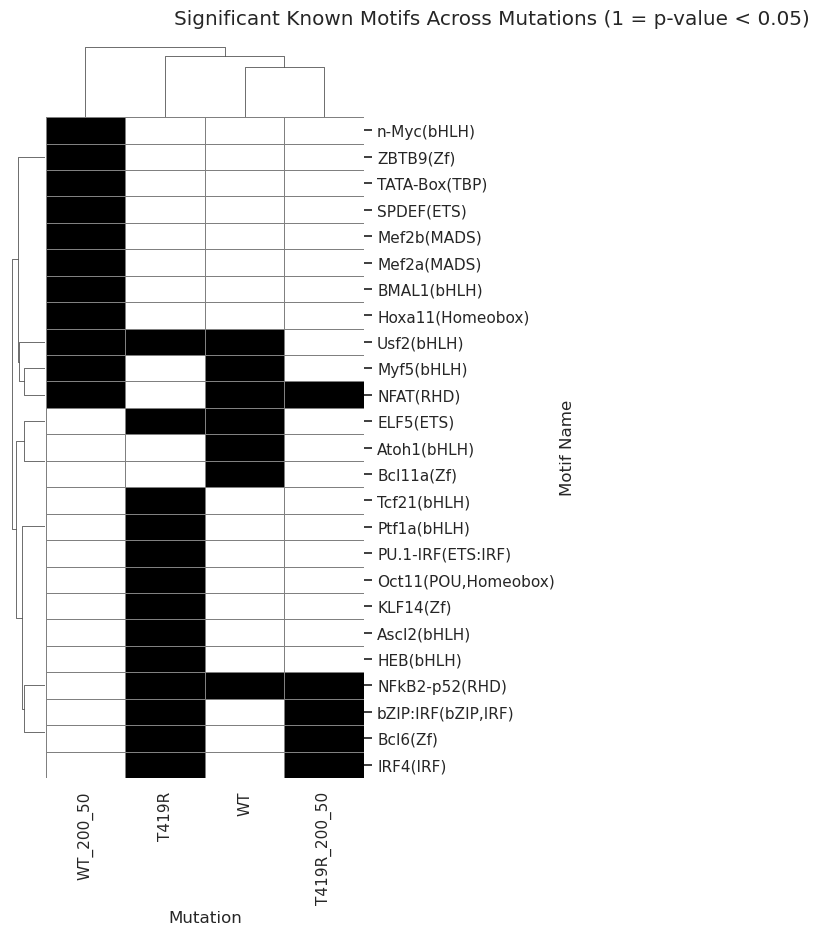

In [238]:
# Filter the DataFrame to include only the specified mutations
mutations_to_include = ['WT', 'WT_200_50', 'T419R', 'T419R_200_50']
filtered_df = df_pivot_bool_filtered[mutations_to_include]

# Remove rows where all values are either 0 or 1
filtered_df = filtered_df[(filtered_df.sum(axis=1) > 0) & (filtered_df.sum(axis=1) < len(mutations_to_include))]

# Create the clustermap
g = sns.clustermap(
    filtered_df,
    method='average',
    metric='euclidean',
    cmap='binary',
    lw=0.5,
    linecolor="gray",
    annot=False,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 8)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.ax_heatmap.set_xticklabels([label.get_text() for label in g.ax_heatmap.get_xticklabels()], rotation=90)

# Add title and axis labels
g.figure.suptitle('Significant Known Motifs Across Mutations (1 = p-value < 0.05)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()